# Model analysis · how and why `decres-rescale-aug10-v1` works
Model: src9 run `decres-rescale-aug10-v1` (transformer4, res decoder, rescale latent, 10% augmentations). Every number below comes from this notebook.

- **Metric**: `iou08` = the repo's `utils.iou08`: IoU of the binary prediction `p > 0.08` with the binary truth `mask > 0.5` on the 64×64 floor mask, per sample, samples with an empty truth skipped. Group values are per-sample means (pooled), as in nb142 / the logged `metrics/eval/{id,ood}/iou08`.
- **ID** = eval categories `id` + `multiple`, **OOD** = `rotated, cylinder, unseen-object, unseen-speaker, unseen-laser, lid` (callbacks.EvalSummary). `unseen-position` is shown on its own.
- **Predictions**: Figures 1, 2 and 4 reuse nb141's fp32 eager predictions (`runs/_src9_cache/nb141/<RUN>/`, all 15891 samples; they reproduce the logged pooled ID .7085 / OOD .3822). Figure 3 runs new eager fp32 forward passes on the CPU (the GPU is busy with the laser-ablation queue); they match nb141's masks to 2e-5. Figure 4's input features are read from the training MDS cache on the CPU. New caches: `runs/_src9_cache/model_analysis/<RUN>/` (first run ≈ 12 min, cached re-run ≈ 15 s).
- Floor positions are mask centres of mass in 64×64 mask pixels (the mask spans the box floor; 1 px = 1/64 of the box width).

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from scipy import ndimage

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())  # repo root
sys.path.insert(0, str(ROOT / "src9"))
sys.path.insert(0, str(ROOT / "figures/src"))
import style
from dataset import CATEGORIES, REGION
from utils import THR

RUN = "decres-rescale-aug10-v1"
BOX = "plastic"
SPEAKER = 1
OBJECT = "candle"
SPLIT = "train"

NB141 = ROOT / "runs/_src9_cache/nb141" / RUN        # fp32 eager masks + metadata of all 15891 samples
CACHE = ROOT / "runs/_src9_cache/model_analysis" / RUN
OUT = ROOT / "figures/src/model_analysis"
CACHE.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

BOXES = ["gastro", "plastic", "cardboard"]
ID_CATS = ["id", "multiple"]
OOD_CATS = ["rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid"]
SHORT = {"red-cube": "cube", "soap dispenser": "soap", "candle": "candle", "vase": "vase", "green-cube+red-cube": "two cubes", "red-cube+vase": "cube + vase", "coffee pot": "coffee pot", "tomato sauce": "tomato sauce"}
PHOTO_FILES = {"gastro": "overhead_empty_box/gastronorm.png", "plastic": "overhead_empty_box/plastic.png", "cardboard": "overhead_empty_box/cardboard.png",
               "candle": "objects/individual/candle.png", "red-cube": "objects/individual/cube.png", "soap dispenser": "objects/individual/soap.png",
               "vase": "objects/individual/vase.png", "green-cube+red-cube": "objects/individual/two_cubes.png", "red-cube+vase": "objects/individual/cube_and_vase.png",
               "coffee pot": "objects/individual/coffee_pot.png", "tomato sauce": "objects/individual/tomato_sauce.png"}
PHOTOS = {name: np.asarray(Image.open(ROOT / "assets" / f).convert("RGBA")) for name, f in PHOTO_FILES.items()}  # box / object photos for the axes
torch.set_num_threads(8)
plt.rcParams.update({"font.size": 12, "svg.fonttype": "none", "axes.spines.top": False, "axes.spines.right": False})
print(ROOT, THR)

Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


/home/ethantu/workspace/good-vibrations 0.08


## 0 · per-sample iou08 from the nb141 cache

In [2]:
meta = pd.read_parquet(NB141 / "meta.parquet")
pred = np.load(NB141 / "masks_pred.npy", mmap_mode="r")
true = np.load(NB141 / "masks_gt.npy") > 0
binary = np.asarray(pred) > THR
inter = (binary & true).sum((1, 2))
union = (binary | true).sum((1, 2))
meta["iou"] = np.where(true.any((1, 2)), inter / np.maximum(union, 1), np.nan)  # = utils.iou08 per sample
category = {f"eval/{box}/{s}": c for box, cats in CATEGORIES.items() for c, splits in cats.items() for s in splits}
meta["cat"] = meta.split.map(category).fillna("train")
meta["n_obj"] = [ndimage.label(t)[1] for t in true]
id_iou = meta[meta.cat.isin(ID_CATS)].iou.mean()
ood_iou = meta[meta.cat.isin(OOD_CATS)].iou.mean()
train_iou = meta[meta.cat == "train"].iou.mean()
print(f"pooled iou08: ID {id_iou:.4f} · OOD {ood_iou:.4f} · train {train_iou:.4f}  (logged at batch 3000: ID .7085, OOD .3822)")
evals = meta[meta.split != "train"]

pooled iou08: ID 0.7084 · OOD 0.3825 · train 0.8903  (logged at batch 3000: ID .7085, OOD .3822)


## Figure 1 · IoU per box
a. by speaker (eval `id` splits; speaker 4 = the unseen speaker, only recorded with the cube: its own split `*-unseen-speaker-unseen`, hatched) ·
b. by floor position (eval `id` + `unseen-position` single-object samples, binned by the true centre of mass into 8×8 px cells; dashed = the held-out region, where no vase trains; circles = the 4 shared floor regions of `style.py`, below: iou08 per region) ·
c. by object (eval `id` + `multiple`) · d. ID vs each unseen condition.

check vs data notebook: base (plastic, speaker 1, candle, train) 202 captures, per region (TL/TR/BL/BR) [16, 17, 18, 23]


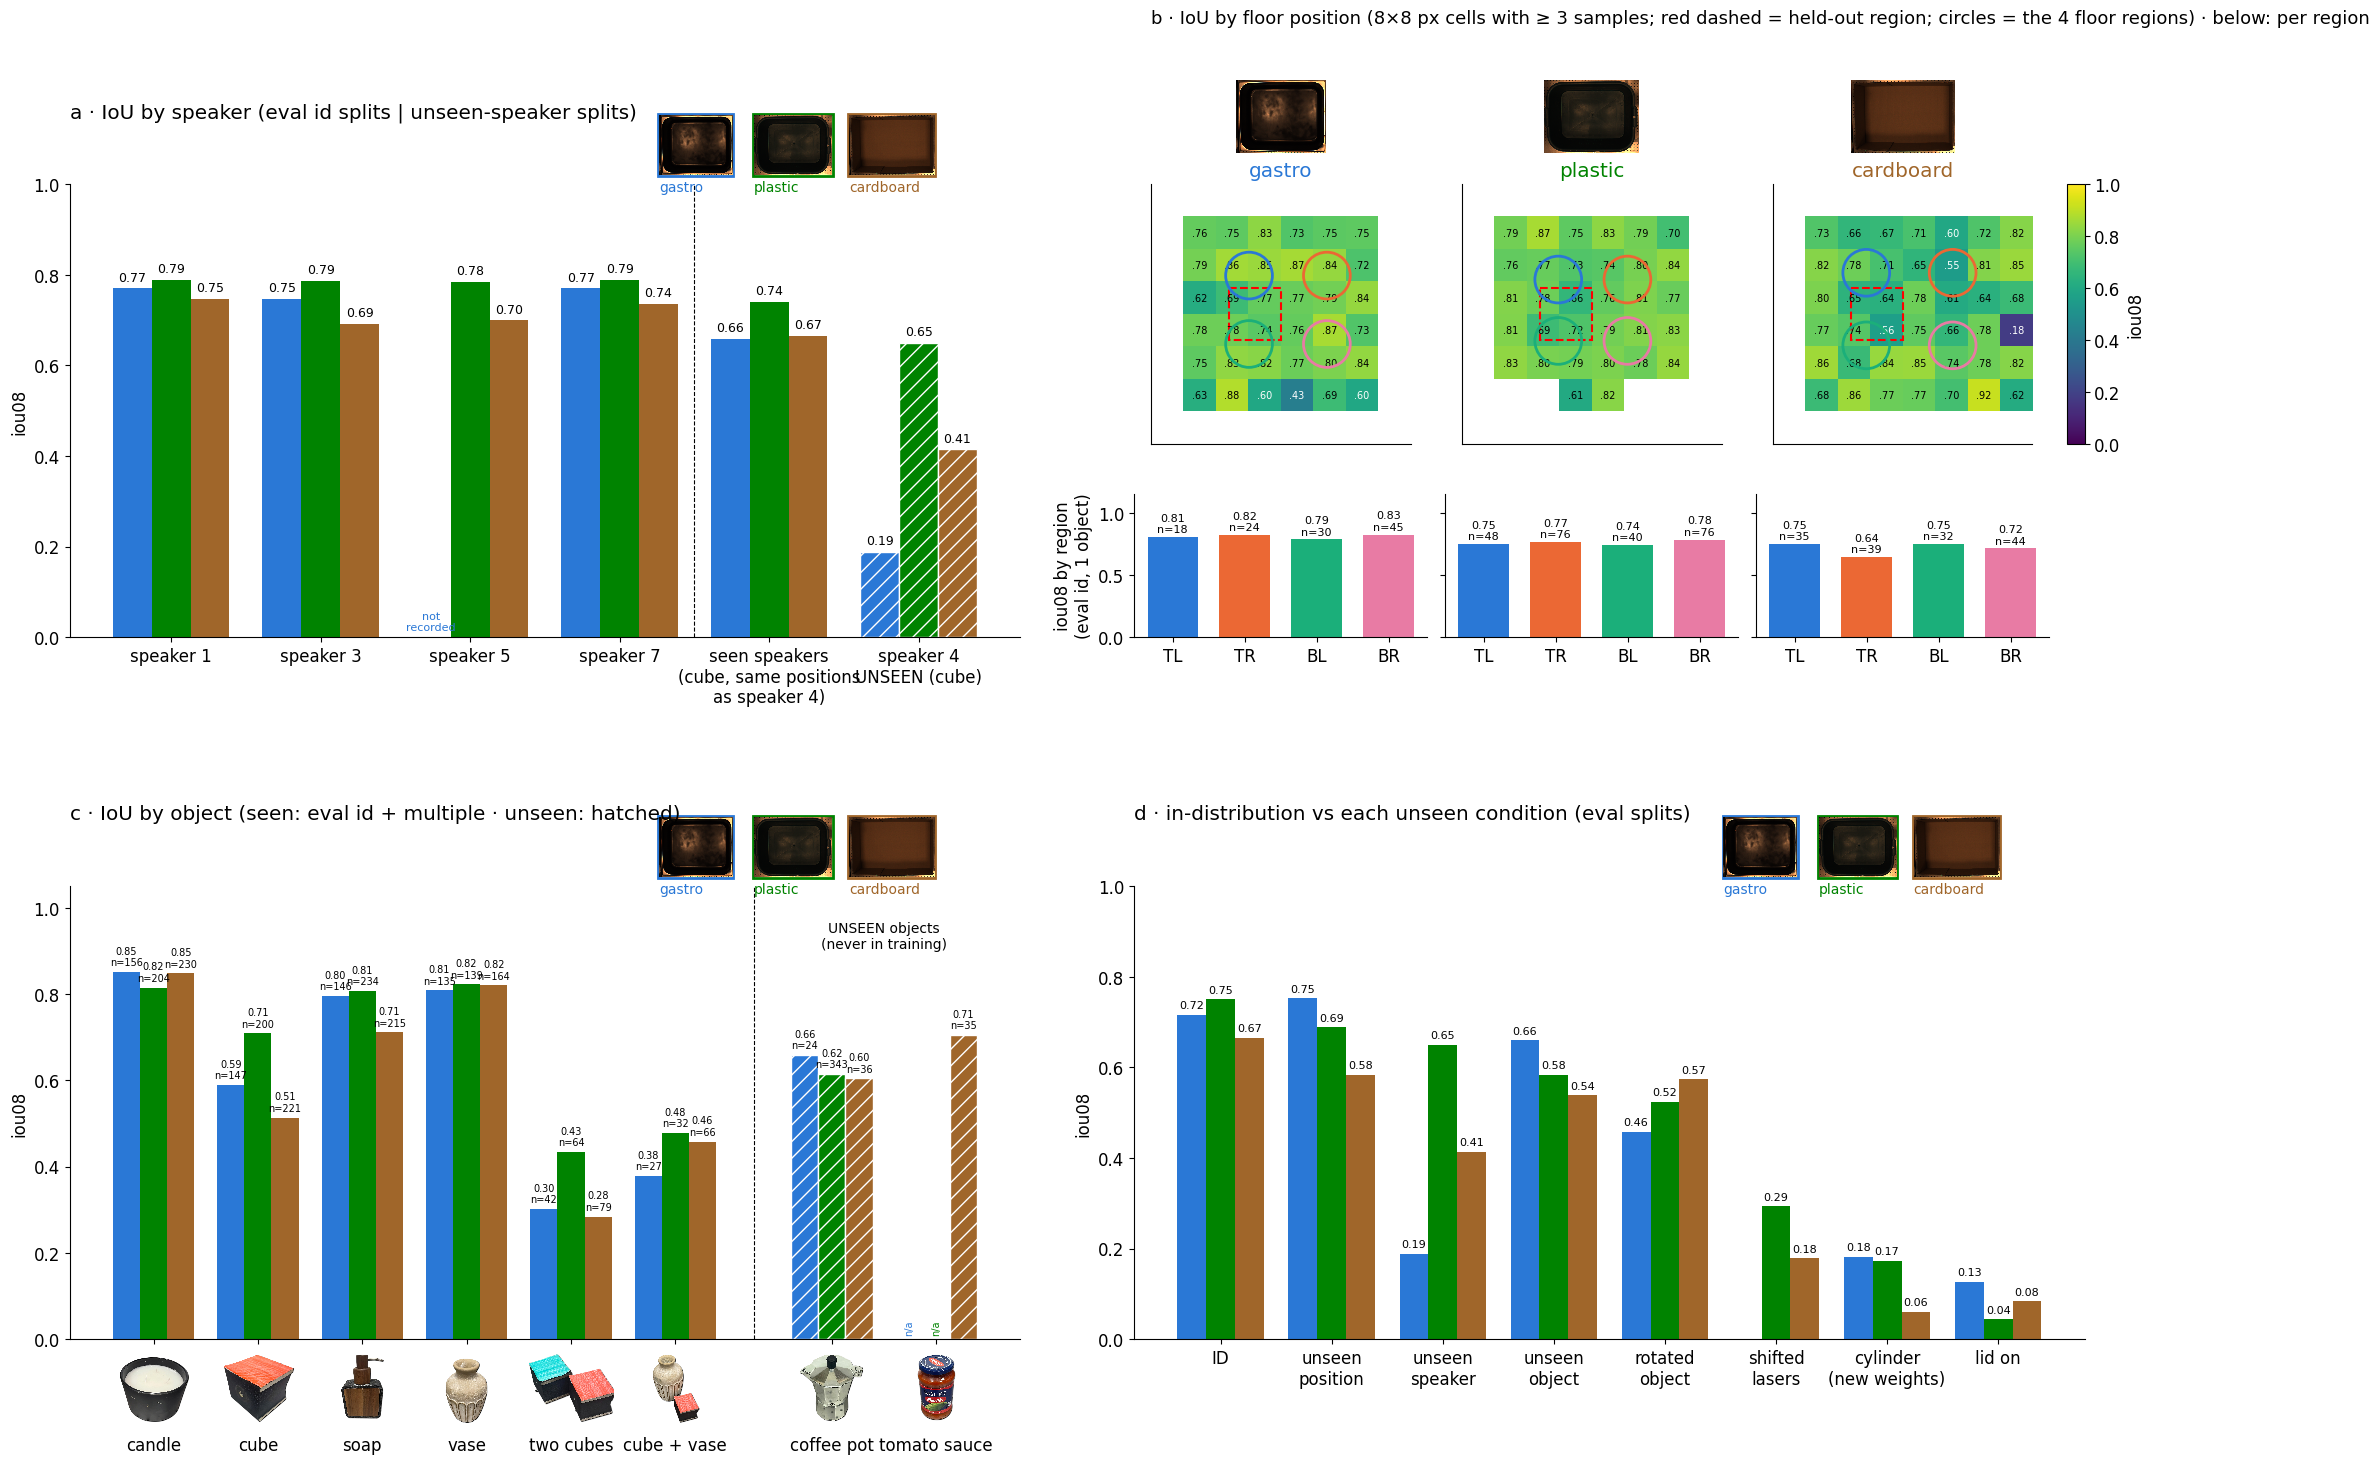

speaker × box (eval id):
box      cardboard  gastro  plastic
speaker                            
1            0.747   0.770    0.790
3            0.692   0.746    0.787
5            0.699     NaN    0.784
7            0.736   0.770    0.788
unseen speaker 4: {'cardboard': 0.414, 'gastro': 0.188, 'plastic': 0.65} n {'cardboard': 10, 'gastro': 35, 'plastic': 40}
same positions, seen speakers (*-unseen-speaker-baseline): {'cardboard': 0.666, 'gastro': 0.659, 'plastic': 0.741}
IoU by region (eval id, single object, true CoM inside the circle):
region     top-left  top-right  bottom-left  bottom-right
box                                                      
cardboard     0.751      0.644        0.750         0.716
gastro        0.806      0.823        0.786         0.826
plastic       0.749      0.765        0.741         0.785
region     top-left  top-right  bottom-left  bottom-right
box                                                      
cardboard        35         39           32     

In [3]:
def bar_labels(ax, bars, fmt="{:.2f}", fontsize=9, rotation=0):
    for b in bars:
        h = b.get_height()
        if np.isfinite(h):
            ax.text(b.get_x() + b.get_width() / 2, h + 0.01, fmt.format(h), ha="center", va="bottom", fontsize=fontsize, rotation=rotation)

def box_legend(ax, x0=0.62, y=1.02, step=0.1, size=0.6):
    # box photos framed in their box colour, as the legend for the bar colours
    for i, box in enumerate(BOXES):
        style.thumbnail(ax, PHOTOS[box], (x0 + i * step, y), size=size, xycoords="axes fraction", color=style.BOX_COLORS[box], box_alignment=(0, 0))
        ax.text(x0 + i * step, y - 0.01, box, transform=ax.transAxes, color=style.BOX_COLORS[box], fontsize=10, va="top")

def group_means(df, keys):
    return df.groupby(keys).iou.agg(["mean", "count"])

width = 0.26
fig = plt.figure(figsize=(26, 15))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1], hspace=0.55, wspace=0.12)

# a · speaker
ax = fig.add_subplot(grid[0, 0])
id_evals = evals[evals.cat == "id"]
speaker_iou = group_means(id_evals, ["box", "speaker"])
unseen_iou = group_means(evals[evals.cat == "unseen-speaker"], ["box"])
control_iou = group_means(evals[evals.split.str.endswith("unseen-speaker-baseline")], ["box"])  # seen speakers at the unseen-speaker positions
speakers = [1, 3, 5, 7]
for j, box in enumerate(BOXES):
    heights = [speaker_iou["mean"].get((box, s), np.nan) for s in speakers] + [control_iou["mean"].get(box, np.nan), unseen_iou["mean"].get(box, np.nan)]
    bars = ax.bar(np.arange(6) + (j - 1) * width, heights, width, color=style.BOX_COLORS[box])
    bars[-1].set_hatch("//")
    bars[-1].set_edgecolor("white")
    bar_labels(ax, bars)
    if not np.isfinite(heights[2]):
        ax.text(2 + (j - 1) * width, 0.01, "not\nrecorded", ha="center", va="bottom", fontsize=8, color=style.BOX_COLORS[box])
ax.axvline(3.5, color="black", lw=0.8, ls="--")
ax.set_xticks(np.arange(6), ["speaker 1", "speaker 3", "speaker 5", "speaker 7", "seen speakers\n(cube, same positions\nas speaker 4)", "speaker 4\nUNSEEN (cube)"])
ax.set_ylabel("iou08")
ax.set_ylim(0, 1)
ax.set_title("a · IoU by speaker (eval id splits | unseen-speaker splits)", loc="left", pad=48)
box_legend(ax, x0=0.62)

# b · floor position heatmaps
CELL = 8
pos_samples = evals[evals.cat.isin(["id", "unseen-position"]) & (evals.n_obj == 1)].copy()
pos_samples["r"] = (pos_samples.y // CELL).astype(int)
pos_samples["c"] = (pos_samples.x // CELL).astype(int)
sub = grid[0, 1].subgridspec(2, 4, width_ratios=[1, 1, 1, 0.06], height_ratios=[1, 0.55], wspace=0.08, hspace=0.25)
# regions: style.REGION_CENTRES circles (radius style.REGION_RADIUS), in the data notebook's coordinates: an object's (row, col) = the mean of the
# sample's metadata CoMs (camera px of the cropped overhead photo) / the crop's (H, W); cached per sample
from dataset import load_meta
region_file = CACHE / "region_coms.parquet"
region_rows = meta.index[meta.x.notna() & (((meta.split != "train") & (meta.n_obj == 1)) | ((meta.split == "train") & (meta.box == BOX) & (meta.speaker == SPEAKER) & (meta.object == OBJECT)))]
region_coms = pd.read_parquet(region_file) if region_file.exists() else None
if region_coms is None or not set(region_rows) <= set(region_coms.index):
    fractions = []
    for d in meta.dir[region_rows]:
        m = load_meta(Path(d))
        H, W = m["crop_overhead_shape"][:2]
        coms = np.array([com[0] for com in m["coms"]], np.float64).reshape(-1, 2)
        fractions.append((coms[:, 0].mean() / H, coms[:, 1].mean() / W))
    region_coms = pd.DataFrame(fractions, index=region_rows, columns=["r", "c"])
    region_coms.to_parquet(region_file)
meta["region_r"] = region_coms.r
meta["region_c"] = region_coms.c
meta["region"] = [style.region_of(r, c, b) if r == r else None for r, c, b in zip(meta.region_r, meta.region_c, meta.box)]
base = meta[(meta.split == "train") & (meta.box == BOX) & (meta.speaker == SPEAKER) & (meta.object == OBJECT)]
base_counts = [int((base.region == name).sum()) for name in style.REGION_NAMES]
print(f"check vs data notebook: base ({BOX}, speaker {SPEAKER}, {OBJECT}, {SPLIT}) {len(base)} captures, per region (TL/TR/BL/BR) {base_counts}")
assert base_counts == [16, 17, 18, 23]
region_samples = meta[(meta.cat == "id") & (meta.n_obj == 1) & meta.region.notna()]  # ID eval, single object, true CoM inside a circle
region_iou = group_means(region_samples, ["box", "region"])
heat = {}
for j, box in enumerate(BOXES):
    g = pos_samples[pos_samples.box == box].groupby(["r", "c"]).iou.agg(["mean", "count"])
    h = np.full((64 // CELL, 64 // CELL), np.nan)
    for (r, c), row in g.iterrows():
        if row["count"] >= 3:
            h[r, c] = row["mean"]
    heat[box] = h
    ax = fig.add_subplot(sub[0, j])
    image = ax.imshow(h, cmap="viridis", vmin=0, vmax=1, extent=(0, 64, 64, 0))
    for r in range(h.shape[0]):
        for c in range(h.shape[1]):
            if np.isfinite(h[r, c]):
                ax.text(c * CELL + CELL / 2, r * CELL + CELL / 2, f"{h[r, c]:.2f}"[1:], ha="center", va="center", fontsize=7, color="white" if h[r, c] < 0.6 else "black")
    r0, r1, c0, c1 = REGION
    ax.add_patch(Rectangle((c0 * 64, r0 * 64), (c1 - c0) * 64, (r1 - r0) * 64, fill=False, ls="--", lw=1.5, color="red"))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(box, color=style.BOX_COLORS[box])
    region_ax = ax.inset_axes([0, 0, 1, 1], xlim=(0, 1), ylim=(1, 0))  # box fractions (x = col, y = row) over the 64 px heatmap
    region_ax.axis("off")
    style.draw_regions(region_ax, box, style.POSITION_COLORS, lw=2.0)
    style.thumbnail(ax, PHOTOS[box], (0.5, 1.12), size=0.73, xycoords="axes fraction", box_alignment=(0.5, 0))
    region_bar_ax = fig.add_subplot(sub[1, j])
    heights = [region_iou["mean"].get((box, q), np.nan) for q in style.REGION_NAMES]
    counts = [region_iou["count"].get((box, q), 0) for q in style.REGION_NAMES]
    bars = region_bar_ax.bar(np.arange(4), heights, 0.7, color=[style.POSITION_COLORS[q] for q in style.REGION_NAMES])
    for bar, value, n in zip(bars, heights, counts):
        region_bar_ax.text(bar.get_x() + 0.35, value + 0.02, f"{value:.2f}\nn={n}", ha="center", va="bottom", fontsize=8)
    region_bar_ax.set_xticks(np.arange(4), ["TL", "TR", "BL", "BR"])
    region_bar_ax.set_ylim(0, 1.15)
    if j == 0:
        region_bar_ax.set_ylabel("iou08 by region\n(eval id, 1 object)")
    else:
        region_bar_ax.set_yticklabels([])
    if j == 0:
        ax.text(0, 1.62, "b · IoU by floor position (8×8 px cells with ≥ 3 samples; red dashed = held-out region; circles = the 4 floor regions) · below: per region", transform=ax.transAxes, fontsize=13)
colorbar = fig.colorbar(image, cax=fig.add_subplot(sub[0, 3]))
colorbar.set_label("iou08")

# c · object (seen objects: eval id + multiple; unseen objects: their unseen-object split, hatched)
ax = fig.add_subplot(grid[1, 0])
seen_objects = ["candle", "red-cube", "soap dispenser", "vase", "green-cube+red-cube", "red-cube+vase"]
unseen_objects = ["coffee pot", "tomato sauce"]
objects = seen_objects + unseen_objects
object_iou = pd.concat([group_means(evals[evals.cat.isin(ID_CATS)], ["box", "object"]),
                        group_means(evals[(evals.cat == "unseen-object") & evals.object.isin(unseen_objects)], ["box", "object"])])
x_objects = np.arange(len(objects)) + (np.arange(len(objects)) >= len(seen_objects)) * 0.5  # a gap before the unseen objects
for j, box in enumerate(BOXES):
    heights = [object_iou["mean"].get((box, o), np.nan) for o in objects]
    counts = [object_iou["count"].get((box, o), 0) for o in objects]
    x = x_objects + (j - 1) * width
    bars = ax.bar(x, heights, width, color=style.BOX_COLORS[box])
    for bar, o, h, n in zip(bars, objects, heights, counts):
        if o in unseen_objects:
            bar.set_hatch("//")
            bar.set_edgecolor("white")
        if np.isfinite(h):
            ax.text(bar.get_x() + width / 2, h + 0.01, f"{h:.2f}\nn={n}", ha="center", va="bottom", fontsize=7)
        else:
            ax.text(bar.get_x() + width / 2, 0.01, "n/a", ha="center", va="bottom", fontsize=7, color=style.BOX_COLORS[box], rotation=90)
ax.axvline((x_objects[len(seen_objects) - 1] + x_objects[len(seen_objects)]) / 2, color="black", lw=0.8, ls="--")
ax.text(x_objects[len(seen_objects):].mean(), 0.97, "UNSEEN objects\n(never in training)", ha="center", va="top", fontsize=10)
ax.set_xticks(x_objects, [SHORT[o] for o in objects])
style.image_ticks(ax, [PHOTOS[o] for o in objects], size=0.7)
ax.set_ylabel("iou08")
ax.set_ylim(0, 1.05)
ax.set_title("c · IoU by object (seen: eval id + multiple · unseen: hatched)", loc="left", pad=48)
box_legend(ax, x0=0.62)

# d · unseen conditions
ax = fig.add_subplot(grid[1, 1])
conditions = [("ID", ID_CATS), ("unseen\nposition", ["unseen-position"]), ("unseen\nspeaker", ["unseen-speaker"]), ("unseen\nobject", ["unseen-object"]),
              ("rotated\nobject", ["rotated"]), ("shifted\nlasers", ["unseen-laser"]), ("cylinder\n(new weights)", ["cylinder"]), ("lid on", ["lid"])]
cond_iou = {}
for j, box in enumerate(BOXES):
    heights = []
    for name, cats in conditions:
        s = evals[(evals.box == box) & evals.cat.isin(cats)]
        heights.append(s.iou.mean() if len(s) else np.nan)
        cond_iou[(box, name.replace("\n", " "))] = (s.iou.mean() if len(s) else np.nan, len(s))
    bars = ax.bar(np.arange(len(conditions)) + (j - 1) * width, heights, width, color=style.BOX_COLORS[box])
    bar_labels(ax, bars, fontsize=8)
ax.set_xticks(np.arange(len(conditions)), [n for n, _ in conditions])
ax.set_ylabel("iou08")
ax.set_ylim(0, 1)
ax.set_title("d · in-distribution vs each unseen condition (eval splits)", loc="left", pad=48)
box_legend(ax, x0=0.62)
fig.savefig(OUT / "iou_per_box.svg", bbox_inches="tight")
plt.show()

print("speaker × box (eval id):")
print(speaker_iou["mean"].unstack(0).round(3).to_string())
print("unseen speaker 4:", unseen_iou["mean"].round(3).to_dict(), "n", unseen_iou["count"].to_dict())
baseline_iou = group_means(evals[evals.split.str.endswith("unseen-speaker-baseline")], ["box"])
print("same positions, seen speakers (*-unseen-speaker-baseline):", baseline_iou["mean"].round(3).to_dict())
print("IoU by region (eval id, single object, true CoM inside the circle):")
region_mean = region_iou["mean"].unstack(1)[style.REGION_NAMES]
print(region_mean.round(3).to_string())
print(region_iou["count"].unstack(1)[style.REGION_NAMES].to_string())
print("region spread (max − min):", (region_mean.max(axis=1) - region_mean.min(axis=1)).round(3).to_dict())
for box in BOXES:
    h = heat[box]
    print(f"{box} floor cells: n {np.isfinite(h).sum()} · min {np.nanmin(h):.2f} · max {np.nanmax(h):.2f} · sd {np.nanstd(h):.3f}")
print("object × box:")
print(object_iou["mean"].unstack(0).round(3).to_string())
print(pd.DataFrame(cond_iou, index=["iou", "n"]).T.unstack(0).round(3).to_string())
print("object × box, n:")
print(object_iou["count"].unstack(0).to_string())
print("mean true area (px of 64×64) per object, eval:", evals[evals.cat.isin(ID_CATS) | evals.object.isin(unseen_objects)].groupby("object").area.mean().round(0).to_dict())

**Claims (Figure 1)**
- **The model is box-agnostic in-distribution.** Pooled ID iou08 is .717 gastro / .750 plastic / .666 cardboard (d); cardboard is the hardest box on every view (lowest ID, worst floor cell .18, floor-cell sd .121 vs .093 gastro / .055 plastic).
- **Seen speakers are interchangeable, the unseen one is not.** The four train speakers lie within .06 per box (plastic .784–.790, gastro .746–.770, cardboard .692–.747; gastro has no speaker 5). At the same cube positions, seen speakers score .659 / .741 / .666 but unseen speaker 4 scores .188 / .650 / .414 (gastro / plastic / cardboard): −.47 in gastro, −.09 in plastic. The speaker is part of what the model learned to read, and it does not transfer equally across boxes.
- **Position is not the bottleneck.** Floor cells range .43–.88 (gastro), .61–.87 (plastic), .18–.92 (cardboard), with no wall or corner trend. The held-out vase region scores as high as ID: unseen-position .753 / .689 / .583 vs ID .717 / .750 / .666, so the model fills in floor positions it never saw a vase at.
- **No floor region is weak, except cardboard's top-right.** The 4 shared floor regions (`style.REGION_CENTRES`, radius 0.09 box fractions, the data notebook's circles; ID eval single-object samples whose true centre of mass lies inside, n = 18–76 per region, so every region has ≥ 10) span .786–.826 in gastro (spread .039), .741–.785 in plastic (.044) and .644 (top-right) – .751 in cardboard (.107). In gastro and plastic that is far smaller than the spread across 8×8 px cells (.43–.88 and .61–.87), so the cell-level dips are local, not a part of the box. Cardboard's top-right region is the one regional dip, where its cells drop to .55–.60.
- **Object size drives object IoU.** Large objects score highest: candle (mean true area 133 px) .82–.85 and vase (78 px) .81–.82, then soap (64 px) .71–.81. The cube (36 px) scores .51–.71, the two-cube scene (72 px split over two blobs) only .28–.44, and cube + vase (115 px) .38–.48.
- **Unseen objects score like seen objects of the same size.**
  - The coffee pot (78 px, never in training) scores .66 gastro (n = 24) / .62 plastic (n = 343) / .60 cardboard (n = 36). That is .15–.21 below the equally large seen vase (.81–.82), but above the smaller seen cube in gastro and cardboard (.59 / .51).
  - Tomato sauce (65 px, cardboard only, n = 35) scores .71, the same as the equally sized seen soap in cardboard (.71).
  - So the model localises new objects with most of its seen-object accuracy.
- **Unseen conditions rank from mild to fatal.** Unseen object .54–.66 and rotated object .46–.57 transfer partly. Shifted lasers .18 / .29 (cardboard / plastic) do not. New cylinder weights (.06–.18; objects of 4–21 px) and a lid on the object (.04–.13) fail almost completely.

## Figure 2 · error types
Classes on the binary prediction b = p > 0.08 (the iou08 threshold), nb132's definitions re-checked against its code: each true object T_k is a connected component of the truth;
every pixel goes to its nearest true object (Voronoi cell V_k). An object is **found** if |b ∩ V_k| ≥ 0.2·|T_k| or b touches T_k; its **main blob** is the connected component of b ∩ V_k that overlaps T_k most (else the largest).
Exclusive class per sample, first match wins:
1. **miss**: no object found (nothing, or < 20% of the object's area, painted in its cell, and nothing touching it)
2. **wrong blob**: a found object's main blob centre is > 0.05·diag = 4.5 px from the object centre
3. **under-paint**: right place, main blob area a < A with |a − A| / (a + A) > 0.2 (a < 0.67·A)
4. **over-paint**: right place, a > 1.5·A by the same rule, or > 20% of b lies outside every main blob (extra blobs)
5. **rough**: right place and size but iou08 < 0.5 (small objects with an offset blob, wrong shape)
6. **hit**: everything else.

Two-object scenes additionally: **both found** = every object found. Eval samples with a non-empty truth only.

In [4]:
D = np.hypot(64, 64)
RR, CC = np.mgrid[:64, :64]

def centre(m):
    return np.array([RR[m].mean(), CC[m].mean()])

def classify(p, y):
    b = p > THR
    labels, n = ndimage.label(y)
    if n == 1:
        cell = np.zeros(y.shape, int)
    else:
        cell = np.stack([ndimage.distance_transform_edt(labels != k) for k in range(1, n + 1)]).argmin(0)
    main = np.zeros_like(b)
    n_found = 0
    wrong_place = False
    under = False
    over = False
    for k in range(n):
        obj = labels == k + 1
        in_cell = b & (cell == k)
        area = obj.sum()
        if not (in_cell.sum() >= 0.2 * area or (in_cell & obj).any()):
            continue
        n_found += 1
        blobs, n_blobs = ndimage.label(in_cell)
        overlap = np.bincount(blobs[obj], minlength=n_blobs + 1)[1:]
        if overlap.max() > 0:
            j = 1 + overlap.argmax()
        else:
            j = 1 + np.bincount(blobs.ravel(), minlength=n_blobs + 1)[1:].argmax()
        blob = blobs == j
        main |= blob
        a = blob.sum()
        if np.linalg.norm(centre(blob) - centre(obj)) / D > 0.05:
            wrong_place = True
        scale = (a - area) / (a + area)
        under |= scale < -0.2
        over |= scale > 0.2
    extra = (b & ~main).sum() / max(b.sum(), 1)
    if n_found == 0:
        kind = "miss"
    elif wrong_place:
        kind = "wrong blob"
    elif under:
        kind = "under-paint"
    elif over or extra > 0.2:
        kind = "over-paint"
    else:
        kind = "hit"
    return kind, n, n_found, int(b.sum() == 0)

KINDS = ["hit", "rough", "over-paint", "under-paint", "wrong blob", "miss"]
KIND_COLOURS = {"hit": "#BFD8B8", "rough": "#E8E3A0", "over-paint": "#F2A65A", "under-paint": "#7FB3D5", "wrong blob": "#C0504D", "miss": "#555555"}
errors_file = CACHE / "error_types.parquet"
if errors_file.exists():
    errors = pd.read_parquet(errors_file)
else:
    scored = evals[true[evals.index].any((1, 2))]
    out = [classify(np.asarray(pred[r]), true[r]) for r in scored.index]
    errors = pd.DataFrame(out, index=scored.index, columns=["kind", "n_obj", "n_found", "empty_pred"])
    errors.to_parquet(errors_file)
errors = errors.join(meta[["box", "cat", "split", "iou", "photo"]])
errors.loc[(errors.kind == "hit") & (errors.iou < 0.5), "kind"] = "rough"
errors["group"] = np.where(errors.cat.isin(ID_CATS), "ID", np.where(errors.cat.isin(OOD_CATS), "OOD", "other"))
print(errors.groupby(["group", "kind"]).iou.agg(["mean", "count"]).round(3).to_string())

                    mean  count
group kind                     
ID    hit          0.788   2051
      over-paint   0.460    108
      rough        0.378    134
      under-paint  0.397     75
      wrong blob   0.186    133
OOD   hit          0.649    559
      miss         0.000     61
      over-paint   0.267    293
      rough        0.380    120
      under-paint  0.346    124
      wrong blob   0.034    250
other hit          0.715    529
      over-paint   0.534     59
      rough        0.403     69
      under-paint  0.412     60
      wrong blob   0.152     35


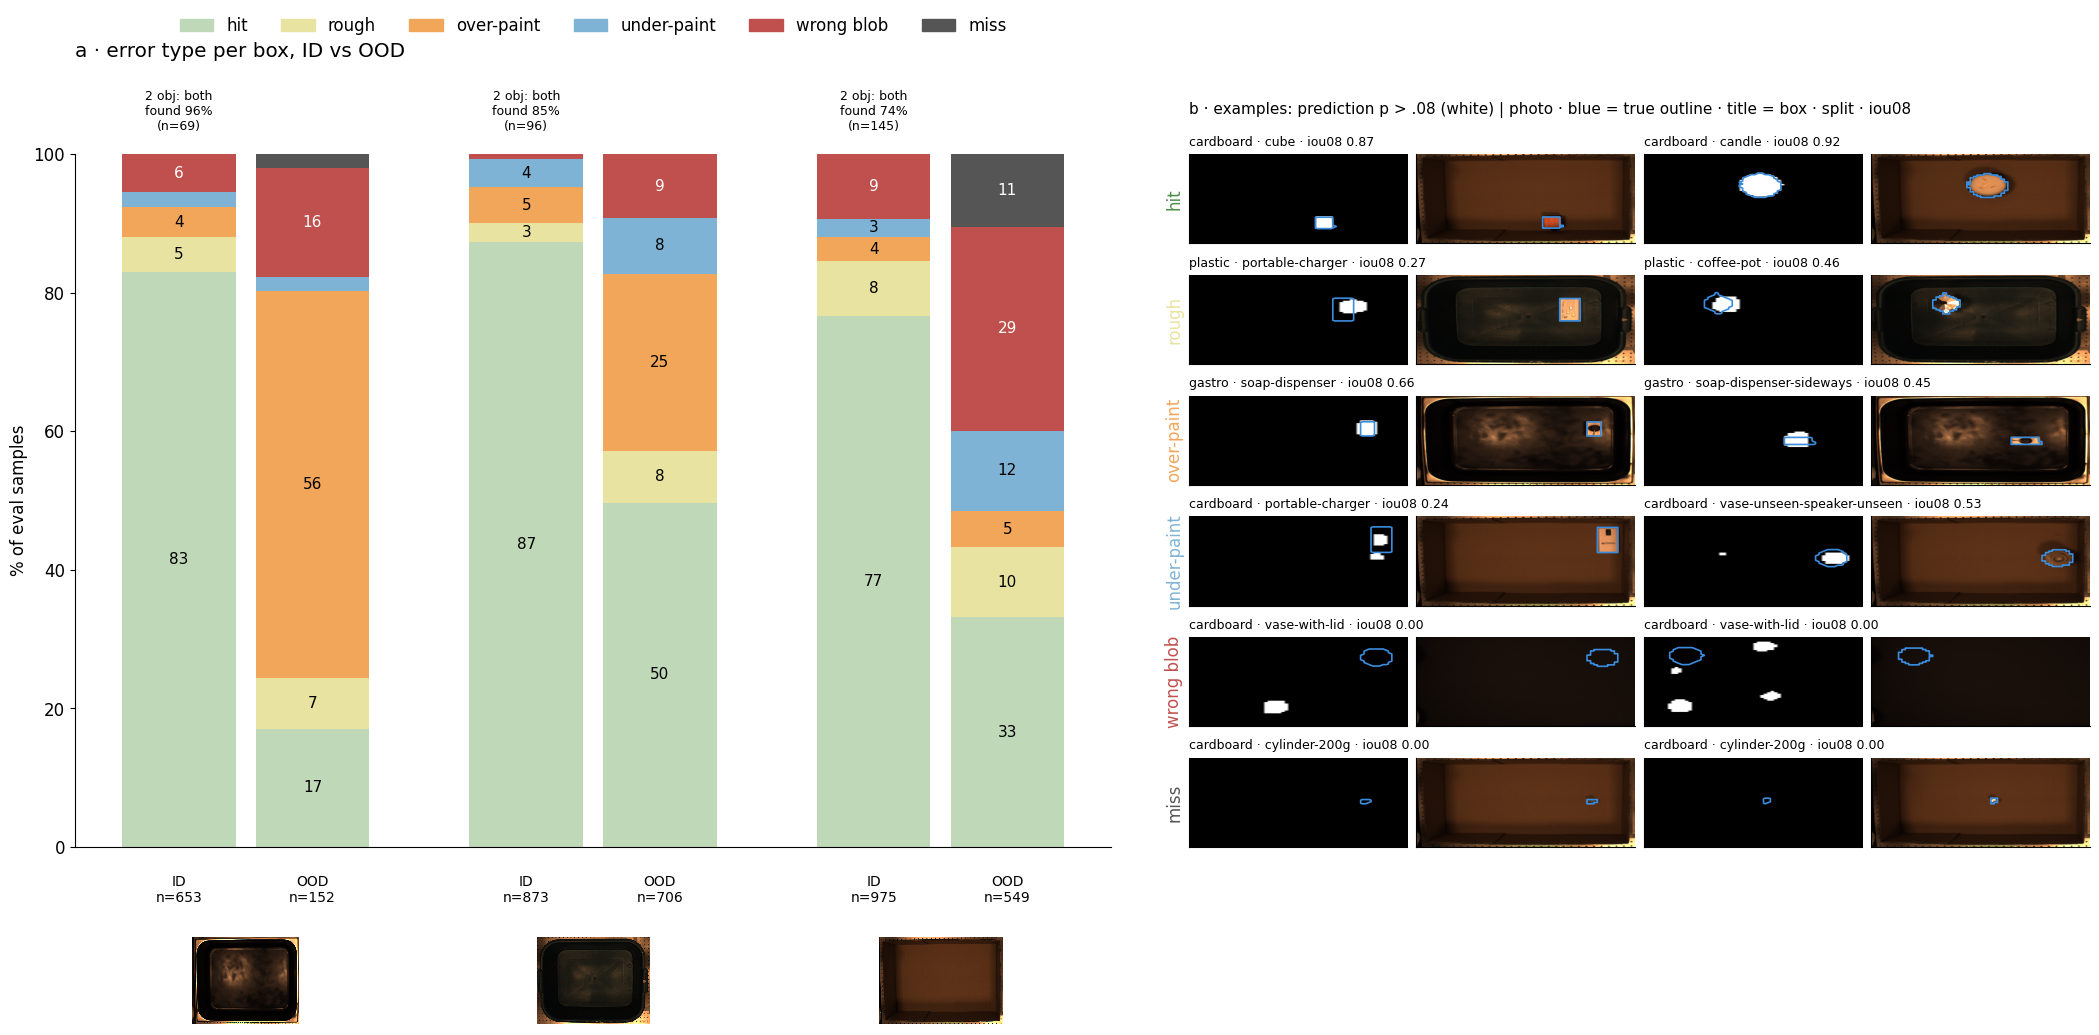

            gastro       plastic       cardboard      
                ID   OOD      ID   OOD        ID   OOD
kind                                                  
hit           83.0  17.1    87.3  49.7      76.6  33.2
rough          5.1   7.2     2.7   7.5       7.9  10.2
over-paint     4.3  55.9     5.2  25.5       3.6   5.1
under-paint    2.1   2.0     4.1   8.1       2.6  11.7
wrong blob     5.5  15.8     0.7   9.2       9.3  29.3
miss           0.0   2.0     0.0   0.0       0.0  10.6
two-object ID scenes, both objects found (%): {'gastro': 95.7, 'plastic': 85.4, 'cardboard': 73.8}
ID: empty prediction 0.0% of samples · of misses nan% are empty · mean iou08 per kind: {'hit': 0.79, 'over-paint': 0.46, 'rough': 0.38, 'under-paint': 0.4, 'wrong blob': 0.19}
OOD: empty prediction 3.8% of samples · of misses 89% are empty · mean iou08 per kind: {'hit': 0.65, 'miss': 0.0, 'over-paint': 0.27, 'rough': 0.38, 'under-paint': 0.35, 'wrong blob': 0.03}


In [5]:
fig = plt.figure(figsize=(26, 9))
grid = fig.add_gridspec(1, 2, width_ratios=[1.15, 1], wspace=0.08)
ax = fig.add_subplot(grid[0, 0])
bars_at = []
shares = {}
for j, box in enumerate(BOXES):
    for k, group in enumerate(["ID", "OOD"]):
        x = j * 2.6 + k
        bars_at.append((x, box, group))
        s = errors[(errors.box == box) & (errors.group == group)]
        share = s.kind.value_counts(normalize=True).reindex(KINDS).fillna(0) * 100
        shares[(box, group)] = share
        bottom = 0
        for kind in KINDS:
            ax.bar(x, share[kind], 0.85, bottom=bottom, color=KIND_COLOURS[kind])
            if share[kind] >= 2.5:
                ax.text(x, bottom + share[kind] / 2, f"{share[kind]:.0f}", ha="center", va="center", fontsize=11, color="white" if kind in ("wrong blob", "miss") else "black")
            bottom += share[kind]
        if group == "ID":
            two = s[s.n_obj == 2]
            both = (two.n_found == 2).mean() * 100
            shares[(box, "both found")] = both
            ax.text(x, 103, f"2 obj: both\nfound {both:.0f}%\n(n={len(two)})", ha="center", va="bottom", fontsize=9)
        ax.text(x, -4, f"{group}\nn={len(s)}", ha="center", va="top", fontsize=10)
    style.thumbnail(ax, PHOTOS[box], (j * 2.6 + 0.5, -0.13), size=0.87, xycoords=("data", "axes fraction"), box_alignment=(0.5, 1.0))
ax.set_xticks([])
ax.set_ylim(0, 100)
ax.set_ylabel("% of eval samples")
ax.legend([Patch(color=KIND_COLOURS[k]) for k in KINDS], KINDS, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.22), frameon=False)
ax.set_title("a · error type per box, ID vs OOD", loc="left", pad=70)

# b · two examples per class (pred mask | photo), OOD + ID, fixed seed
sub = grid[0, 1].subgridspec(len(KINDS), 4, wspace=0.04, hspace=0.35)
rng = np.random.default_rng(0)
examples = {}
for i, kind in enumerate(KINDS):
    candidates = errors[(errors.kind == kind) & (errors.group != "other") & (errors.n_obj == 1)]
    pool = candidates[meta.area[candidates.index] >= 40].index.to_numpy()  # objects ≥ 40 px, so they are visible
    if len(pool) < 2:
        pool = candidates.index.to_numpy()
    picks = rng.choice(pool, 2, replace=False)
    examples[kind] = picks
    for e, r in enumerate(picks):
        ax_pred = fig.add_subplot(sub[i, 2 * e])
        ax_photo = fig.add_subplot(sub[i, 2 * e + 1])
        photo = Image.open(meta.photo[r]).convert("RGB")
        ax_pred.imshow(np.asarray(pred[r]) > THR, cmap="gray", vmin=0, vmax=1, aspect="auto", extent=(0, photo.size[0], photo.size[1], 0))
        ax_pred.contour(np.linspace(0, photo.size[0], 64), np.linspace(0, photo.size[1], 64), true[r], levels=[0.5], colors=["#3A8DDE"], linewidths=1.2)
        ax_photo.imshow(photo, aspect="auto")
        ax_photo.contour(np.asarray(Image.fromarray(true[r].astype(np.uint8) * 255).resize(photo.size, Image.NEAREST)) > 127, levels=[0.5], colors=["#3A8DDE"], linewidths=1.2)
        for a in (ax_pred, ax_photo):
            a.set_xticks([])
            a.set_yticks([])
        ax_pred.set_title(f"{meta.box[r]} · {meta.split[r].split('/')[-1]} · iou08 {meta.iou[r]:.2f}", fontsize=9, loc="left")
        if e == 0:
            ax_pred.set_ylabel(kind, fontsize=12, color=KIND_COLOURS[kind] if kind != "hit" else "#4C8C4A")
        if i == 0 and e == 0:
            ax_pred.text(0, 1.45, "b · examples: prediction p > .08 (white) | photo · blue = true outline · title = box · split · iou08", transform=ax_pred.transAxes, fontsize=11)
fig.savefig(OUT / "error_types.svg", bbox_inches="tight")
plt.show()

both_found = {box: float(shares.pop((box, "both found"))) for box in BOXES}
print(pd.DataFrame(shares).round(1).to_string())
print("two-object ID scenes, both objects found (%):", {box: round(v, 1) for box, v in both_found.items()})
for group in ["ID", "OOD"]:
    s = errors[errors.group == group]
    print(f"{group}: empty prediction {100 * s.empty_pred.mean():.1f}% of samples · of misses {100 * s[s.kind == 'miss'].empty_pred.mean():.0f}% are empty · mean iou08 per kind:",
          s.groupby("kind").iou.mean().round(2).to_dict())

**Claims (Figure 2)**
- **ID errors are rare and mostly about extent, not location.** 83 / 87 / 77% of ID samples are hits (gastro / plastic / cardboard). Their mean iou08 is .79, versus .19 for wrong blobs. No ID sample is a miss, and none has an empty prediction (0.0%).
- **The second object is the ID weak spot in cardboard.** On two-object ID scenes, both objects are found in 96% (gastro, n = 69), 85% (plastic, n = 96) and 74% (cardboard, n = 145).
- **OOD failures differ by box.**
  - Gastro OOD is mostly **over-paint** (56%; its OOD set is cylinders, unseen speaker, coffee pot, the sideways soap and lids).
  - Cardboard OOD is mostly **wrong blob** (29%) plus **miss** (11%).
  - Plastic OOD stays 50% hits.
- **Misses are tiny objects.** Across all eval sets there are 61 misses: 59 are cylinders (median object area 6 px), and 89% of OOD misses have an empty prediction. The model does not hallucinate when it cannot see an object; it stays silent.

## Figure 3a · frequency sensitivity per band
The per-band version of Figure 3b's "drop 1 band" bar. It reuses nb136's masking cache `runs/_src9_cache/nb136/q1_train.npz`: 720 ID single-object **train** samples, 60 per box × object, all train speakers.
- `mask_b` = per-sample ΔIoU (unmasked iou08 − iou08 with one of the 18 bands masked through `m_b`, the train-time token dropout).
- `clean` = the unmasked iou08.

The spectra come from `runs/_src9_cache/frequency_sensitivity/spectra_train.npz` (the cache that `figures/src/analysis/analysis.py` `frequency_panel()` reads).

What the figure shows:
- **Bars** = mean IoU lost when that band is masked, as % of the box's mean unmasked IoU. A band is 65 bins ≈ 50 Hz; centres are 125 … 975 Hz.
- **Line** = the box's mean z-scored |FFT| (each sample (spec − its mean) / its σ, the model's per-sample normalisation, averaged over the box's samples). Its highest peak is labelled.
- **Black outline** = the band that contains that resonance, with its importance rank (1 = most important of 18).
- **Right panel**: cumulative share of the box's total sensitivity when the bands are sorted from most to least important. Dashed line at 90%.

Cross-check: Figure 3b's "drop 1 band" bar is this same masking averaged over the 18 bands, on a different sample set (plastic · speaker 1 · candle, 202 samples). Section 3b prints the agreement with this cache on the samples the two sets share.

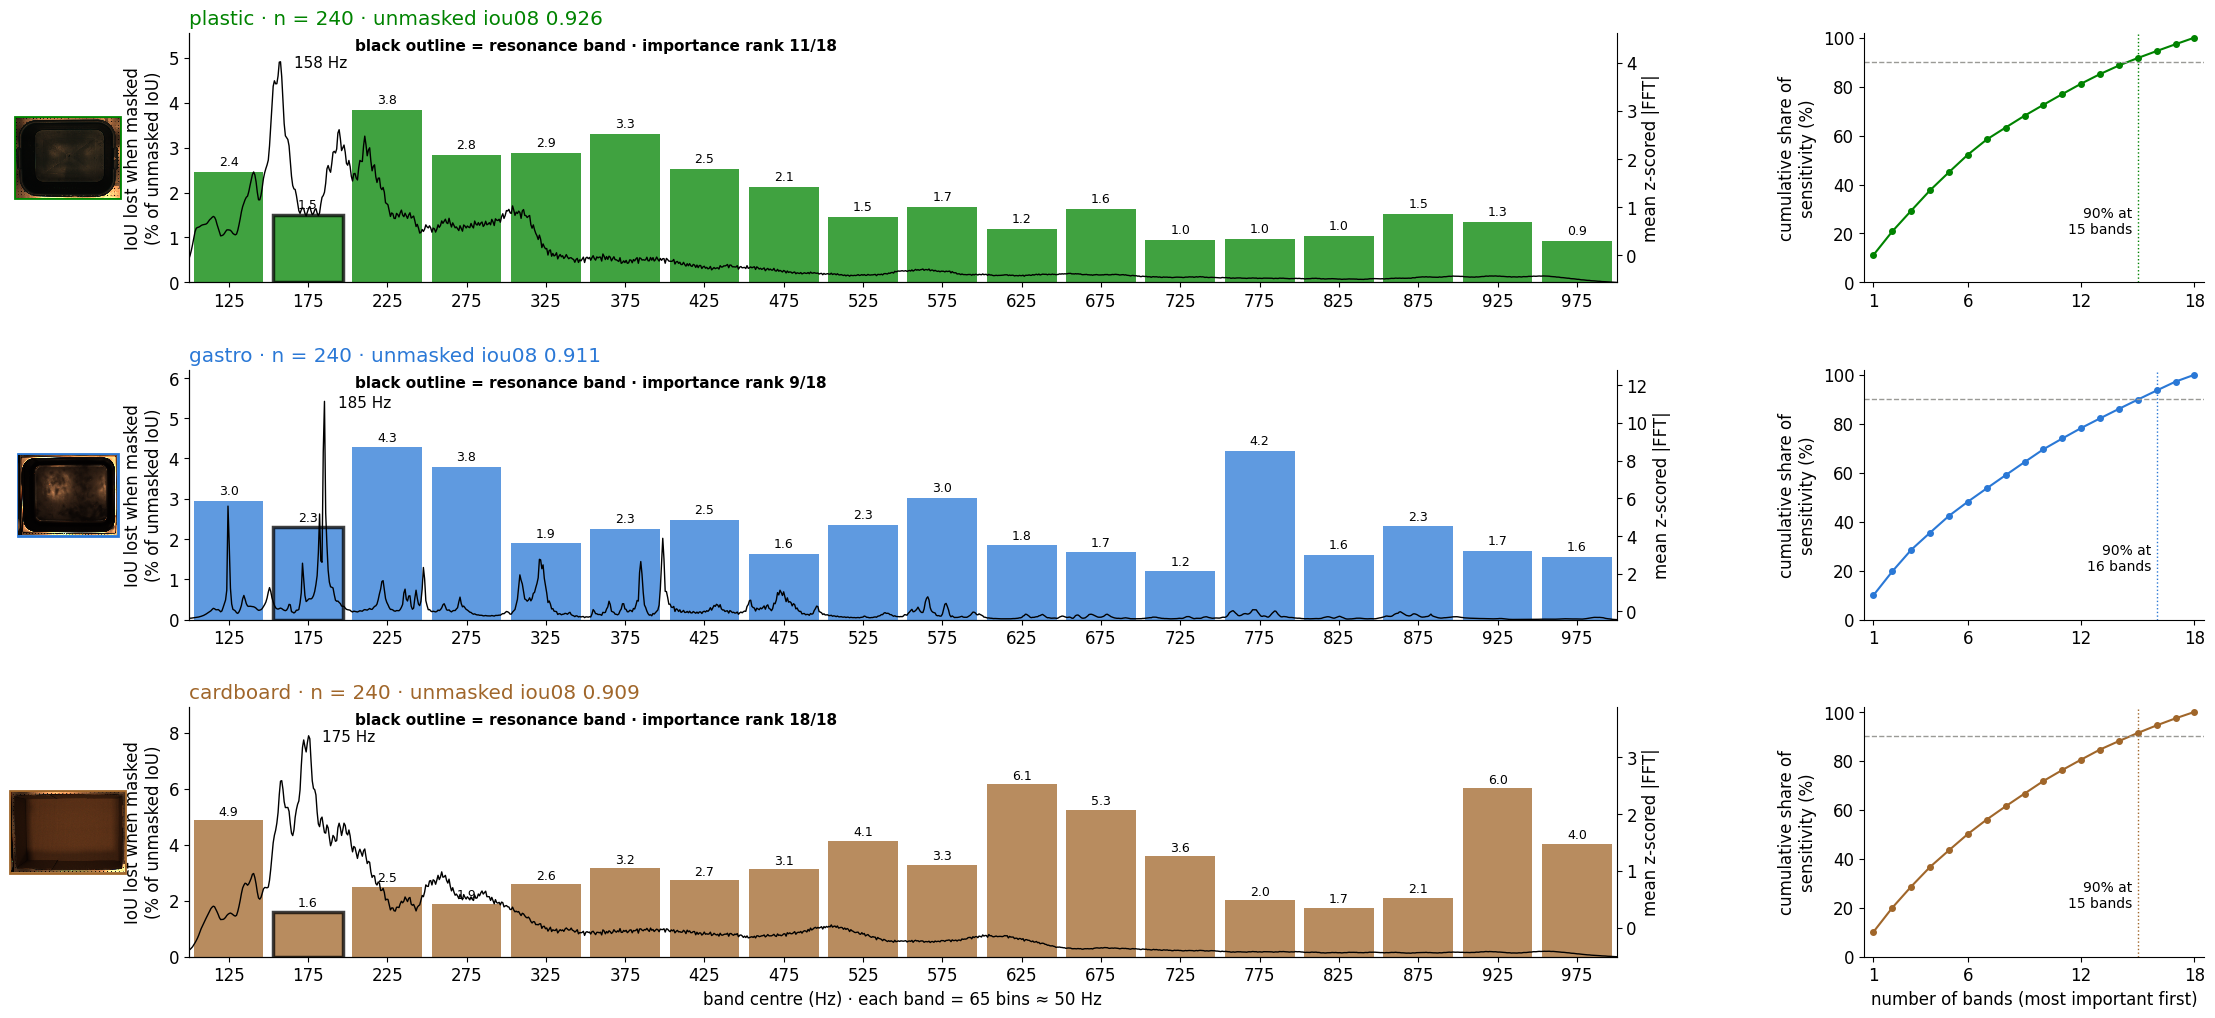

           max_loss max_band_hz     top2_hz     peak_hz resonant_band_hz resonant_rank resonant_loss bands_to_90 mean_loss    n clean_iou
plastic    3.831216         225  (225, 375)   157.74166              175            11      1.495754          15  1.898329  240  0.926106
gastro     4.276331         225  (225, 775)  185.457656              175             9      2.291451          16  2.390684  240  0.911029
cardboard  6.148337         625  (625, 925)  175.449102              175            18      1.598346          15  3.374384  240  0.908773


In [6]:
q1 = np.load(ROOT / "runs/_src9_cache/nb136/q1_train.npz")
spectra = np.load(ROOT / "runs/_src9_cache/frequency_sensitivity/spectra_train.npz")
assert (spectra["rows"] == q1["rows"]).all()
assert (meta.pos[q1["rows"]].to_numpy() == q1["pos"]).all()  # q1 rows index the same nb141 meta rows
FREQ_HZ = np.linspace(100, 1000, 1170)
BAND_HZ = 125 + 50 * np.arange(18)
FREQ_BOXES = ["plastic", "gastro", "cardboard"]

band_loss = {}       # box -> (18,) % of the unmasked IoU lost when that band is masked
box_spectrum = {}    # box -> (1170,) mean z-scored |FFT|
for box in FREQ_BOXES:
    in_box = q1["box"] == box
    band_loss[box] = q1["mask_b"][in_box].mean(0) / q1["clean"][in_box].mean() * 100
    spec = spectra["spec"][in_box]
    sigma = spectra["sig"][in_box][:, None]
    box_spectrum[box] = ((spec - spec.mean(1, keepdims=True)) / sigma).mean(0)

fig = plt.figure(figsize=(26, 12))
grid = fig.add_gridspec(3, 2, width_ratios=[4.2, 1], hspace=0.35, wspace=0.28)
freq_table = {}
for r, box in enumerate(FREQ_BOXES):
    loss = band_loss[box]
    spectrum = box_spectrum[box]
    peak_hz = FREQ_HZ[spectrum.argmax()]
    peak_band = int((peak_hz - 100) // 50)
    order = np.argsort(-loss)
    rank = int(np.where(order == peak_band)[0][0]) + 1
    cumulative = np.cumsum(loss[order]) / loss.sum() * 100
    n90 = int(np.searchsorted(cumulative, 90) + 1)
    freq_table[box] = dict(max_loss=loss.max(), max_band_hz=BAND_HZ[loss.argmax()], top2_hz=tuple(int(h) for h in BAND_HZ[order[:2]]), peak_hz=peak_hz,
                           resonant_band_hz=BAND_HZ[peak_band], resonant_rank=rank, resonant_loss=loss[peak_band], bands_to_90=n90, mean_loss=loss.mean(),
                           n=int((q1["box"] == box).sum()), clean_iou=q1["clean"][q1["box"] == box].mean())

    ax = fig.add_subplot(grid[r, 0])
    bars = ax.bar(BAND_HZ, loss, 44, color=style.BOX_COLORS[box], alpha=0.75)
    bars[peak_band].set_edgecolor("black")
    bars[peak_band].set_linewidth(2.5)
    for bar, value in zip(bars, loss):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.08, f"{value:.1f}", ha="center", va="bottom", fontsize=9)
    ax.text(BAND_HZ[peak_band] + 30, loss.max() * 1.42, f"black outline = resonance band · importance rank {rank}/18", ha="left", va="top", fontsize=11, fontweight="bold")
    ax.set_xlim(100, 1000)
    ax.set_ylim(0, loss.max() * 1.45)
    ax.set_ylabel("IoU lost when masked\n(% of unmasked IoU)")
    ax.set_xticks(BAND_HZ)
    if r == len(FREQ_BOXES) - 1:
        ax.set_xlabel("band centre (Hz) · each band = 65 bins ≈ 50 Hz")
    ax.set_title(f"{box} · n = {freq_table[box]['n']} · unmasked iou08 {freq_table[box]['clean_iou']:.3f}", loc="left", color=style.BOX_COLORS[box])
    style.thumbnail(ax, PHOTOS[box], (-0.085, 0.5), size=0.8, xycoords="axes fraction", color=style.BOX_COLORS[box])

    line_ax = ax.twinx()
    line_ax.plot(FREQ_HZ, spectrum, color="black", lw=1)
    line_ax.annotate(f"{peak_hz:.0f} Hz", (peak_hz, spectrum.max()), xytext=(10, -4), textcoords="offset points", fontsize=11)
    line_ax.set_ylabel("mean z-scored |FFT|")
    line_ax.spines["right"].set_visible(True)
    line_ax.set_ylim(spectrum.min(), spectrum.max() * 1.15)

    cum_ax = fig.add_subplot(grid[r, 1])
    cum_ax.plot(np.arange(1, 19), cumulative, "o-", color=style.BOX_COLORS[box], ms=4)
    cum_ax.axhline(90, color=style.NOISE_COLOR, ls="--", lw=1)
    cum_ax.axvline(n90, color=style.BOX_COLORS[box], ls=":", lw=1)
    cum_ax.text(n90 - 0.3, 20, f"90% at\n{n90} bands", ha="right", fontsize=10)
    cum_ax.set_xlim(0.5, 18.5)
    cum_ax.set_ylim(0, 102)
    cum_ax.set_xticks([1, 6, 12, 18])
    cum_ax.set_ylabel("cumulative share of\nsensitivity (%)")
    if r == len(FREQ_BOXES) - 1:
        cum_ax.set_xlabel("number of bands (most important first)")
fig.savefig(OUT / "frequency_sensitivity.svg", bbox_inches="tight")
plt.show()
freq_summary = pd.DataFrame(freq_table).T
print(freq_summary.to_string())

**Claims (Figure 3a)** (720 train samples, 240 per box)
- **No single band is critical.** The largest IoU loss from masking one band is 3.8% in plastic (225 Hz), 4.3% in gastro (225 Hz) and 6.1% in cardboard (625 Hz). The mean over all 18 bands is 1.9% / 2.4% / 3.4%.
- **The dominant resonance is not what the model reads.** The loudest peak of the mean spectrum is at 158 Hz in plastic, 185 Hz in gastro and 175 Hz in cardboard. Its band (150–200 Hz) ranks only 11 / 9 / 18 of 18 in importance.
- **The evidence is spread over almost all bands.** Reaching 90% of the total sensitivity takes 15 / 16 / 15 of the 18 bands.
- **The important bands differ by box.** The top two bands are 225 + 375 Hz (plastic), 225 + 775 Hz (gastro) and 625 + 925 Hz (cardboard).
- **Why the model is this robust (an inference, not an ablation here).** Training masks bands itself: 10% of samples (`--band-drop-p 0.1`) get each band token dropped with p = 0.2. The model is therefore trained to predict without any given band, which likely explains the small, flat per-band losses. Figure 3b shows the same at the sample-set level: dropping one band keeps 98.6%, while swapping two bands, which never happens in training, costs 6.5%.

## Figure 3b · stress tests on the training samples of (BOX, SPEAKER, OBJECT)
Samples: every `SPLIT` sample with box = BOX, speaker = SPEAKER, object = OBJECT. New eager fp32 forward passes on the CPU (`model.eval()`, no augmentation), iou08 per sample; bar = mean iou08 / unperturbed mean iou08 × 100.

The model input x is (100 lasers on a 10×10 grid, 1170 bins over 100–1000 Hz = 0.77 Hz/bin, 2 channels), the linear |FFT| divided by its std over the sample; the model z-scores each sample over everything, then cuts 18 bands × 65 bins (50 Hz each).

**In-distribution** (the model's own token dropout, transformer4 `drop()`: during training 10% of samples (`--laser-drop-p` / `--band-drop-p 0.1`) get each laser / band token masked with prob 0.2, the mask enters `m_l` / `m_b`): drop 1 band (mean over each of the 18; the per-band breakdown on a larger, all-box sample set is Figure 3a), drop 1 laser (mean over each of the 100). Same masks, same code path.

**Never seen in training** (bars = mean over instances, whiskers = min..max over instances):
- frequency: swap two 65-bin bands (10 random pairs), shuffle all 18 bands (5 random permutations), Gaussian smoothing along frequency σ = 2 / 8 / 32 bins (1.5 / 6.2 / 25 Hz, `scipy.ndimage.gaussian_filter1d`, mode nearest), shift the frequency axis by ±1 / ±2 bins (edge bin repeated), mask 50% of the bands at once (9 of 18, 5 random sets)
- laser: swap two lasers (10 random pairs), shuffle all lasers (5 permutations), mirror the 10×10 grid left↔right and up↔down, mask 50% of the lasers (5 random sets)
- noise: add Gaussian noise of 1× / 3× the measured repeat noise σ(laser, bin, channel) (3 seeds; values clipped at 0). σ = std of the difference of back-to-back empty-box captures of BOX with SPEAKER (consecutive position ids) / √2, in the same units as x.
- gain: whole-sample gain × 0.5 / × 2, and a random gain per laser, log-uniform in [0.5, 2] (3 seeds).

In [7]:
MODEL = None
JOBS = None

def get_model():
    # the trained model (CPU, eval, fp32) and nb141's (split, dataset, index) row order, so row r of meta = JOBS[r]
    global MODEL, JOBS
    if MODEL is None:
        from dataset import build_dataset
        from arch.transformer4 import Transformer4
        args = json.load(open(ROOT / "runs" / RUN / "args.json"))
        _, eval_sets, train_set, info = build_dataset(args["window"], num_workers=0)
        model = Transformer4(info, decoder=args["decoder"], latent_norm=args["latent_norm"], freq_rope=args["freq_rope"])
        checkpoint = torch.load(ROOT / "runs" / RUN / "checkpoints/latest-rank0.pt", map_location="cpu", weights_only=False)
        print(model.load_state_dict(checkpoint["state"]["model"]))
        MODEL = model.eval()
        splits = [("train", train_set.dataloader.dataloader.dataset)] + [(e.label, e.dataloader.dataloader.dataset) for e in eval_sets]
        JOBS = [(name, subset.dataset, i) for name, subset in splits for i in subset.indices]
        assert [j[0] for j in JOBS] == list(meta.split), "row order differs from nb141"
    return MODEL

def raw_x(r):
    # the model input of meta row r (100, 1170, 2), read straight from the MDS row
    from streaming import StreamingDataset
    _, dataset, i = JOBS[r]
    return torch.from_numpy(StreamingDataset.__getitem__(dataset, i)["X"].copy())

def freq_stage(x):
    # Encoder.forward up to the per-laser freq tokens f (B, 100, 256), every band kept
    enc = MODEL.encoder
    x = (x - x.mean((1, 2, 3), keepdim=True)) / (x.std((1, 2, 3), keepdim=True) + 1e-6)
    x = x.reshape(*x.shape[:2], enc.n_bands, 65, -1).flatten(-2)
    m_b = torch.ones(len(x), enc.n_bands, dtype=torch.bool)
    return enc.freq_enc(enc.embed(x), m_b)

def laser_stage(f, m_l):
    u = MODEL.encoder.laser_enc(f, m_l)
    return MODEL.decoder(u, None, m_l).sigmoid()

def full(x, m_b=None):
    B = len(x)
    m_l = torch.ones(B, 100, dtype=torch.bool)
    if m_b is None:
        m_b = torch.ones(B, 18, dtype=torch.bool)
    u = MODEL.encoder(x, m_l, m_b)
    return MODEL.decoder(u, None, m_l).sigmoid()

def iou08(p, y):
    b = p > THR
    return ((b & y).flatten(1).sum(1) / (b | y).flatten(1).sum(1).clamp_min(1)).numpy()

In [8]:
stress_rows = meta.index[(meta.split == SPLIT) & (meta.box == BOX) & (meta.speaker == SPEAKER) & (meta.object == OBJECT)].to_numpy()
stress_file = CACHE / f"stress_{SPLIT}_{BOX}_{SPEAKER}_{OBJECT}.parquet"
print(len(stress_rows), "samples")
GRID = np.arange(100).reshape(10, 10)
rng = np.random.default_rng(0)
band_pairs = [rng.choice(18, 2, replace=False) for _ in range(10)]
band_perms = [rng.permutation(18) for _ in range(5)]
band_halves = [rng.choice(18, 9, replace=False) for _ in range(5)]
laser_pairs = [rng.choice(100, 2, replace=False) for _ in range(10)]
laser_perms = [rng.permutation(100) for _ in range(5)]
laser_halves = [rng.choice(100, 50, replace=False) for _ in range(5)]
laser_gains = [np.exp(rng.uniform(np.log(0.5), np.log(2), 100)).astype(np.float32) for _ in range(3)]

def band_permute(x, order):
    # new band b = old band order[b] (65-bin blocks)
    blocks = x.reshape(*x.shape[:2], 18, 65, x.shape[-1])
    return blocks[:, :, torch.as_tensor(order)].reshape(x.shape)

def swap(n, pair):
    order = np.arange(n)
    order[pair[0]], order[pair[1]] = pair[1], pair[0]
    return order

def shift(x, k):
    # move the spectrum k bins up (k > 0) or down, repeating the edge bin
    if k > 0:
        return torch.cat([x[:, :, :1].expand(-1, -1, k, -1), x[:, :, :-k]], 2)
    return torch.cat([x[:, :, -k:], x[:, :, -1:].expand(-1, -1, -k, -1)], 2)

def smooth(x, sigma):
    return torch.from_numpy(ndimage.gaussian_filter1d(x.numpy(), sigma, axis=2, mode="nearest"))

def repeat_noise():
    # back-to-back empty-box captures of BOX with SPEAKER (consecutive position ids): sigma = std(x_i+1 - x_i) / sqrt(2) per (laser, bin, channel)
    empty = meta[(meta.object == "empty") & (meta.box == BOX) & (meta.speaker == SPEAKER) & (meta.split == "train")].sort_values("pos")
    pairs = [(a, b) for (a, pa), (b, pb) in zip(empty.pos.items(), list(empty.pos.items())[1:]) if pb == pa + 1]
    diffs = torch.stack([raw_x(b) - raw_x(a) for a, b in pairs])
    return diffs.pow(2).mean(0).div(2).sqrt(), len(pairs)

def masked_bands(drop_bands, B):
    m_b = torch.ones(B, 18, dtype=torch.bool)
    m_b[:, torch.as_tensor(np.atleast_1d(drop_bands))] = False
    return m_b

def masked_lasers(drop_lasers, B):
    m_l = torch.ones(B, 100, dtype=torch.bool)
    m_l[:, torch.as_tensor(np.atleast_1d(drop_lasers))] = False
    return m_l

if stress_file.exists():
    stress = pd.read_parquet(stress_file)
    noise_info = json.load(open(CACHE / f"repeat_noise_{BOX}_{SPEAKER}.json"))
else:
    get_model()
    sigma, n_pairs = repeat_noise()
    noise_info = dict(n_pairs=n_pairs, sigma_over_x_rms=0.0)
    records = []
    started = time.time()
    with torch.no_grad():
        for start in range(0, len(stress_rows), 16):
            chunk = stress_rows[start:start + 16]
            x = torch.stack([raw_x(r) for r in chunk])
            y = torch.from_numpy(true[chunk])
            B = len(x)
            assert torch.equal(torch.stack([torch.from_numpy(JOBS[r][1][JOBS[r][2]]["mask_true"].numpy() > 0.5) for r in chunk[:2]]), y[:2])
            noise_info["sigma_over_x_rms"] += float(sigma.pow(2).mean().sqrt() / x.pow(2).mean().sqrt()) * B / len(stress_rows)
            results = []  # (family, condition, instance, predicted masks)
            f = freq_stage(x)
            base = laser_stage(f, torch.ones(B, 100, dtype=torch.bool))
            results.append(("baseline", "baseline", 0, base))
            noise_info["max_diff_vs_nb141"] = max(noise_info.get("max_diff_vs_nb141", 0.0), float((base - torch.from_numpy(np.asarray(pred[chunk]))).abs().max()))
            for b in range(18):
                results.append(("in-dist", "drop 1 band", b, full(x, masked_bands(b, B))))
            for l in range(100):
                results.append(("in-dist", "drop 1 laser", l, laser_stage(f, masked_lasers(l, B))))
            for i, pair in enumerate(band_pairs):
                results.append(("frequency", "swap 2 bands", i, full(band_permute(x, swap(18, pair)))))
            for i, order in enumerate(band_perms):
                results.append(("frequency", "shuffle bands", i, full(band_permute(x, order))))
            for s in (2, 8, 32):
                results.append(("frequency", f"smooth σ={s} bins", 0, full(smooth(x, s))))
            for k in (-2, -1, 1, 2):
                results.append(("frequency", f"shift {k:+d} bin", 0, full(shift(x, k))))
            for i, half in enumerate(band_halves):
                results.append(("frequency", "mask 50% bands", i, full(x, masked_bands(half, B))))
            for i, pair in enumerate(laser_pairs):
                order = swap(100, pair)
                results.append(("laser", "swap 2 lasers", i, laser_stage(f[:, order], torch.ones(B, 100, dtype=torch.bool))))
            for i, order in enumerate(laser_perms):
                results.append(("laser", "shuffle lasers", i, laser_stage(f[:, order], torch.ones(B, 100, dtype=torch.bool))))
            results.append(("laser", "mirror left↔right", 0, laser_stage(f[:, GRID[:, ::-1].ravel()], torch.ones(B, 100, dtype=torch.bool))))
            results.append(("laser", "mirror up↔down", 0, laser_stage(f[:, GRID[::-1, :].ravel()], torch.ones(B, 100, dtype=torch.bool))))
            for i, half in enumerate(laser_halves):
                results.append(("laser", "mask 50% lasers", i, laser_stage(f, masked_lasers(half, B))))
            for level in (1, 3):
                for seed in range(3):
                    generator = torch.Generator().manual_seed(seed * 1000 + start)
                    noisy = (x + level * sigma * torch.randn(x.shape, generator=generator)).clamp_min(0)
                    results.append(("noise", f"noise {level}× repeat σ", seed, full(noisy)))
            for gain in (0.5, 2.0):
                p = full(x * gain)
                noise_info[f"max_diff_gain_{gain}"] = max(noise_info.get(f"max_diff_gain_{gain}", 0.0), float((p - base).abs().max()))
                results.append(("gain", f"gain ×{gain:g}", 0, p))
            for i, g in enumerate(laser_gains):
                results.append(("gain", "random gain per laser", i, full(x * torch.from_numpy(g)[None, :, None, None])))
            for family, condition, instance, p in results:
                for r, value in zip(chunk, iou08(p, y)):
                    records.append(dict(family=family, condition=condition, instance=instance, row=r, iou=value))
            print(f"{start + B}/{len(stress_rows)} · {time.time() - started:.0f} s", flush=True)
    stress = pd.DataFrame(records)
    stress.to_parquet(stress_file)
    json.dump(noise_info, open(CACHE / f"repeat_noise_{BOX}_{SPEAKER}.json", "w"))
print(noise_info)

202 samples
{'n_pairs': 10, 'sigma_over_x_rms': 0.022567825668519087, 'max_diff_vs_nb141': 2.16066837310791e-05, 'max_diff_gain_0.5': 1.519918441772461e-05, 'max_diff_gain_2.0': 1.1712312698364258e-05}


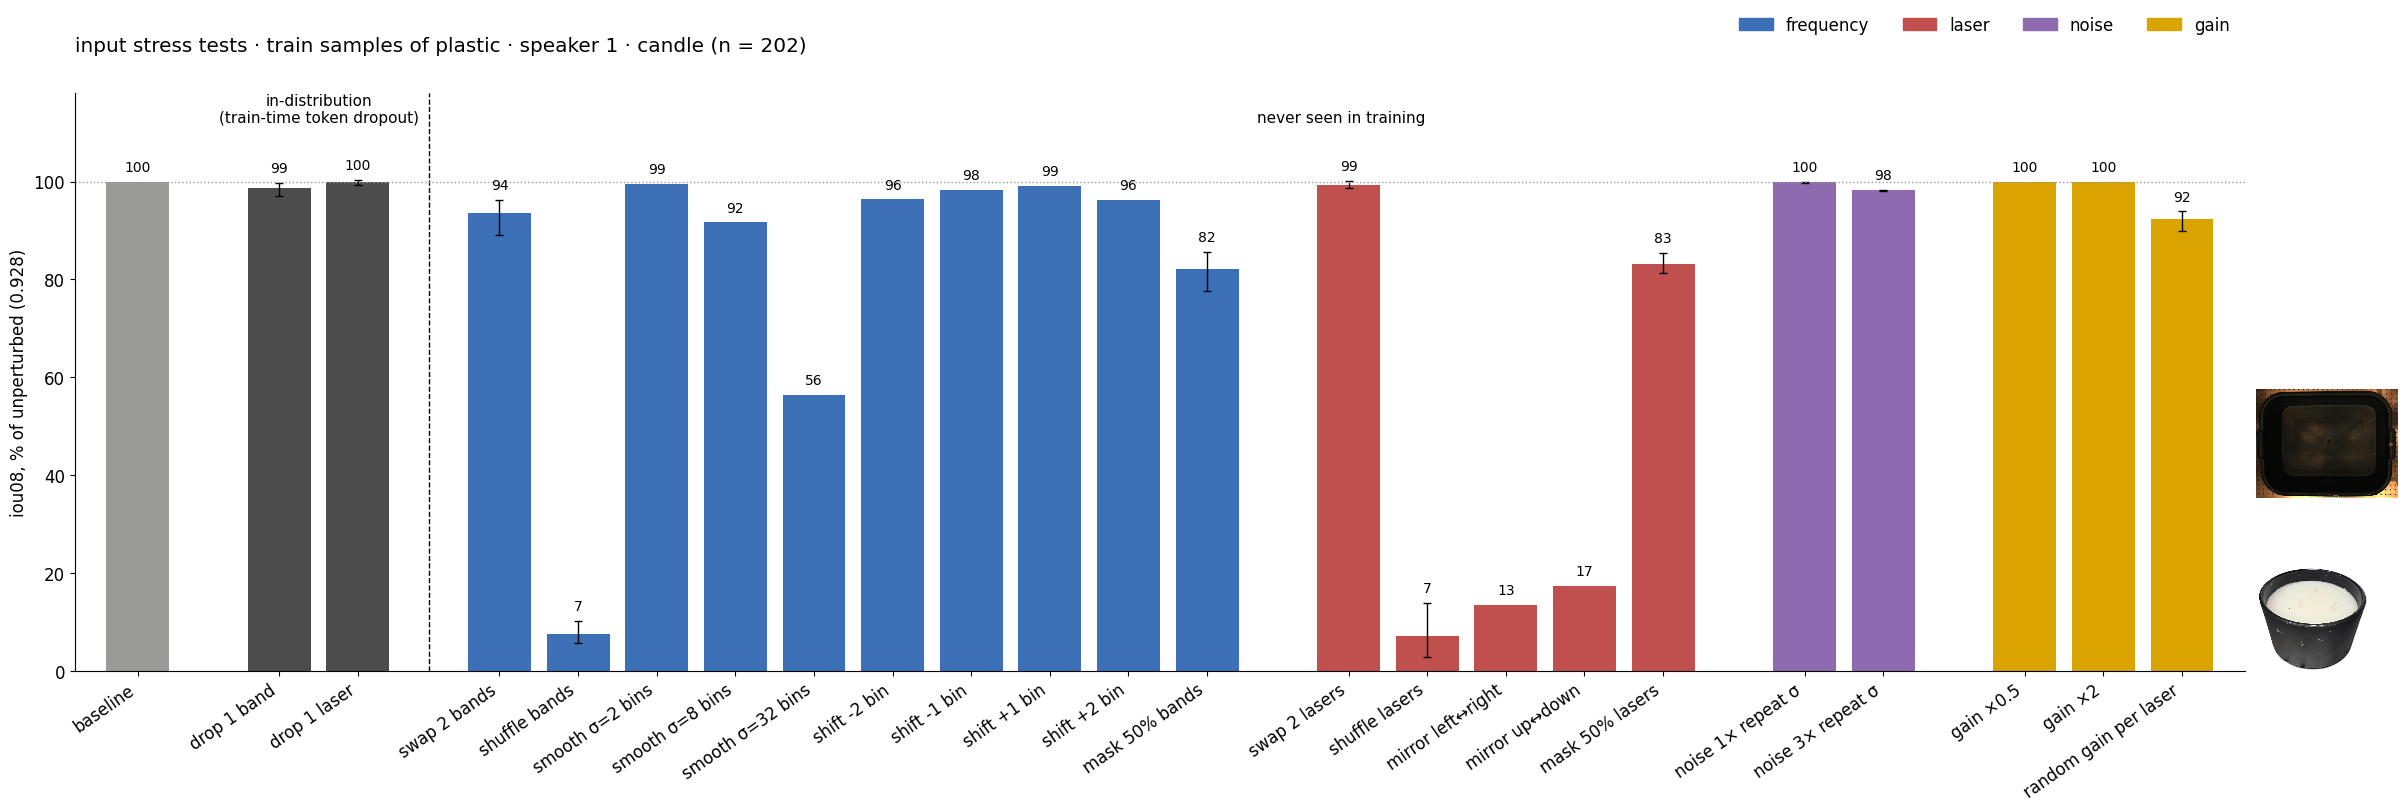

       family              condition        mean         min         max  count
0    baseline               baseline  100.000000  100.000000  100.000000      1
1     in-dist            drop 1 band   98.599998   97.000000   99.699997     18
2     in-dist           drop 1 laser   99.800003   99.400002  100.400002    100
3   frequency           swap 2 bands   93.500000   89.000000   96.199997     10
4   frequency          shuffle bands    7.500000    5.700000   10.200000      5
5   frequency        smooth σ=2 bins   99.500000   99.500000   99.500000      1
6   frequency        smooth σ=8 bins   91.599998   91.599998   91.599998      1
7   frequency       smooth σ=32 bins   56.500000   56.500000   56.500000      1
8   frequency           shift -2 bin   96.300003   96.300003   96.300003      1
9   frequency           shift -1 bin   98.300003   98.300003   98.300003      1
10  frequency           shift +1 bin   99.099998   99.099998   99.099998      1
11  frequency           shift +2 bin   9

In [9]:
FAMILY_COLOURS = {"baseline": style.NOISE_COLOR, "in-dist": "#4C4C4C", "frequency": "#3B6FB6", "laser": "#C0504D", "noise": "#8E6BB0", "gain": "#D9A400"}
per_instance = stress.groupby(["family", "condition", "instance"], sort=False).iou.mean().reset_index()
base_iou = per_instance[per_instance.condition == "baseline"].iou.iloc[0]
per_instance["rel"] = per_instance.iou / base_iou * 100
summary = per_instance.groupby(["family", "condition"], sort=False).rel.agg(["mean", "min", "max", "count"]).reset_index()
order = list(FAMILY_COLOURS)
summary["family_rank"] = summary.family.map(order.index)
summary = summary.sort_values("family_rank", kind="stable").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(28, 7.5))
x_pos = []
x = 0
previous = None
for _, row in summary.iterrows():
    if previous is not None and row.family != previous:
        x += 0.8
        if previous in ("baseline", "in-dist") and row.family not in ("baseline", "in-dist"):
            ax.axvline(x - 0.9, color="black", lw=1, ls="--")
    x_pos.append(x)
    previous = row.family
    x += 1
summary["x"] = x_pos
bars = ax.bar(summary.x, summary["mean"], 0.8, color=summary.family.map(FAMILY_COLOURS))
has_range = summary["count"] > 1
ax.errorbar(summary.x[has_range], summary["mean"][has_range], yerr=[summary["mean"][has_range] - summary["min"][has_range], summary["max"][has_range] - summary["mean"][has_range]],
            fmt="none", ecolor="black", elinewidth=1, capsize=3)
for _, row in summary.iterrows():
    ax.text(row.x, max(row["max"], row["mean"]) + 1.5, f"{row['mean']:.0f}", ha="center", va="bottom", fontsize=10)
ax.axhline(100, color=style.NOISE_COLOR, lw=1, ls=":")
ax.set_xticks(summary.x, summary.condition, rotation=35, ha="right")
ax.set_ylabel(f"iou08, % of unperturbed ({base_iou:.3f})")
ax.set_ylim(0, 118)
ax.set_xlim(-0.8, summary.x.max() + 0.8)
ax.text(summary.x[summary.family == "in-dist"].mean(), 112, "in-distribution\n(train-time token dropout)", ha="center", fontsize=11)
ax.text((summary.x[summary.family == "frequency"].min() + summary.x.max()) / 2, 112, "never seen in training", ha="center", fontsize=11)
ax.legend([Patch(color=FAMILY_COLOURS[f]) for f in order[2:]], order[2:], ncol=4, loc="upper right", bbox_to_anchor=(1, 1.16), frameon=False)
ax.set_title(f"input stress tests · {SPLIT} samples of {BOX} · speaker {SPEAKER} · {OBJECT} (n = {len(stress_rows)})", loc="left", pad=30)
style.thumbnail(ax, PHOTOS[OBJECT], (1.005, 0.0), size=1.09, xycoords="axes fraction", box_alignment=(0, 0))
style.thumbnail(ax, PHOTOS[BOX], (1.005, 0.3), size=1.09, xycoords="axes fraction", box_alignment=(0, 0))
fig.savefig(OUT / "stress_tests.svg", bbox_inches="tight")
plt.show()
print(summary[["family", "condition", "mean", "min", "max", "count"]].round(1).to_string())
band_drop = per_instance[per_instance.condition == "drop 1 band"].sort_values("rel")
print("worst single bands (index, Hz range, %):", [(int(b), f"{100 + 50 * b}-{150 + 50 * b} Hz", round(v, 1)) for b, v in zip(band_drop.instance[:3], band_drop.rel[:3])])
laser_drop = per_instance[per_instance.condition == "drop 1 laser"].sort_values("rel")
print("worst single lasers (id, %):", [(int(l), round(v, 1)) for l, v in zip(laser_drop.instance[:3], laser_drop.rel[:3])], "· lasers below 95%:", int((laser_drop.rel < 95).sum()))

# agreement with nb136's masking cache (Figure 3a) on the samples both sets contain
shared = np.intersect1d(q1["rows"], stress_rows)
q1_index = {r: i for i, r in enumerate(q1["rows"])}
mine_base = stress[stress.condition == "baseline"].set_index("row").iou
mine_band = stress[stress.condition == "drop 1 band"].pivot(index="row", columns="instance", values="iou")
mine_delta = mine_base[shared].to_numpy()[:, None] - mine_band.loc[shared].to_numpy()
q1_delta = np.stack([q1["mask_b"][q1_index[r]] for r in shared])
q1_clean = np.array([q1["clean"][q1_index[r]] for r in shared])
print(f"shared samples: {len(shared)} · unmasked iou08 here vs nb136: max |diff| {np.abs(mine_base[shared].to_numpy() - q1_clean).max():.4f}"
      f" · per-band ΔIoU max |diff| {np.abs(mine_delta - q1_delta).max():.4f}")

**Claims (Figure 3b)** (n = 202 train samples, plastic · speaker 1 · candle; unperturbed iou08 .928)
- **Token dropout makes single bands and lasers redundant (in-distribution).**
  - Dropping any one band keeps 98.6% of the IoU (worst: 100–150 Hz, 97.0%). That 1.4% loss is the mean of the per-band bars for this sample set; Figure 3a breaks it down per band on 720 samples over all boxes and objects, where plastic averages 1.9%. On the 15 samples both sets share, the two computations agree exactly (max |ΔIoU difference| 0.0000).
  - Dropping any one laser keeps 99.8% (worst 99.4%; no laser below 95%).
  - Even masking 50% of the bands or of the lasers (more than the training rate of 20% on 10% of samples) keeps 82% / 83%.
- **Band identity matters: the model reads which band a pattern is in.**
  - Shuffling the 18 bands collapses the IoU to 7.5% (5 permutations, 5.7–10.2%).
  - Swapping just two bands costs 6.5% (89–96%), several times more than deleting a band (1.4%).
  - So a band carrying the wrong content hurts more than a missing band: the model relies on band order and position (rope over band index), not on a bag of spectral peaks.
- **Laser layout matters globally but not locally.**
  - Shuffling all lasers gives 7.2%; mirroring the grid gives 13.4% (left↔right) and 17.3% (up↔down).
  - Swapping two random lasers costs only 0.7%.
  - So the model decodes position from the spatial pattern across the whole grid, not from any single laser.
- **Peak sharpness matters only at coarse scales.** Gaussian smoothing along frequency keeps 99.5% at σ = 2 bins (1.5 Hz), 91.6% at σ = 8 bins (6.2 Hz) and 56.5% at σ = 32 bins (25 Hz). Shifting the spectrum by ±1 / ±2 bins (0.8 / 1.5 Hz) keeps 98–99% / 96%. The information sits in the band-level spectral shape at a few-Hz resolution, not in exact peak positions.
- **Measurement noise is not a threat.** The back-to-back repeat noise σ (10 empty-box pairs) is 2.3% of the input's rms. Adding 1× / 3× that noise keeps 99.8% / 98.2%.
- **Gain: the per-sample z-score cancels a global gain exactly.** ×0.5 and ×2 keep 100.0%, with a max |Δp| of 1.5e-5 (float noise). A random gain per laser (log-uniform 0.5–2) is not cancelled and costs 7.6%: the relative loudness between lasers carries information.

## Figure 4 · interpolation
a. iou08 vs the distance from the sample's true centre of mass to the nearest **training** sample of the same object in the same box (64×64 mask px; single-object eval samples of objects that train in that box), binned; dashed = the position-oracle copy (below) in the same bins.
b. copy baselines: predict an eval sample by copying the true mask of one training sample of the same box:
- **input NN**: nearest in input space: cosine on the z-scored model input, frequency averaged over 10-bin blocks (100 lasers × 117 × 2 = 23400 features)
- **latent NN**: nearest by cosine on the model's own 512-d latent u (nb141 cache)
- **position oracle**: nearest true centre of mass among the training samples of the same object (any object if it never trains in that box): uses the answer
- **best copy oracle**: the training mask with the highest IoU: the ceiling of any copy-a-training-mask method

Copied masks are binary, so their IoU is plain IoU with the truth; the model is its iou08.

In [10]:
feature_file = CACHE / "input_features_pool10.npy"
if feature_file.exists():
    features = np.load(feature_file, mmap_mode="r")
else:
    get_model()
    features = np.zeros((len(meta), 100 * 117 * 2), np.float16)
    started = time.time()
    for r in range(len(meta)):
        x = raw_x(r)
        x = (x - x.mean()) / (x.std() + 1e-6)
        v = x.reshape(100, 117, 10, 2).mean(2).flatten()
        features[r] = (v / v.norm()).numpy()
        if r % 2000 == 0:
            print(r, f"{time.time() - started:.0f} s", flush=True)
    np.save(feature_file, features)
latents = np.load(NB141 / "latents.npy")
latents = latents / np.linalg.norm(latents, axis=1, keepdims=True)

In [11]:
copy_file = CACHE / "copy_baselines.parquet"
if copy_file.exists():
    copies = pd.read_parquet(copy_file)
else:
    flat = true.reshape(len(true), -1).astype(np.float32)
    area = flat.sum(1)
    object_of = meta.object.to_numpy()
    com_x = meta.x.to_numpy()
    com_y = meta.y.to_numpy()
    columns = {}

    def copy_iou(r, t):
        # plain IoU of the binary true mask of row r with the copied true mask of training row t
        return float((true[r] & true[t]).sum() / max((true[r] | true[t]).sum(), 1))

    for box in BOXES:
        train_rows = meta.index[(meta.split == "train") & (meta.box == box)].to_numpy()
        eval_rows = evals.index[(evals.box == box) & true[evals.index].any((1, 2))].to_numpy()
        train_features = np.asarray(features[train_rows], np.float32)
        for start in range(0, len(eval_rows), 512):
            rows = eval_rows[start:start + 512]
            nn_input = train_rows[(np.asarray(features[rows], np.float32) @ train_features.T).argmax(1)]
            nn_latent = train_rows[(latents[rows] @ latents[train_rows].T).argmax(1)]
            overlap = flat[rows] @ flat[train_rows].T
            iou_all = overlap / (area[rows][:, None] + area[train_rows][None] - overlap).clip(1)
            for k, r in enumerate(rows):
                same = train_rows[object_of[train_rows] == object_of[r]]
                seen_object = len(same) > 0
                if not seen_object:
                    same = train_rows[area[train_rows] > 0]
                d = np.hypot(com_x[same] - com_x[r], com_y[same] - com_y[r])
                nn_position = same[np.nanargmin(d)]
                columns[r] = dict(input_nn=copy_iou(r, nn_input[k]), latent_nn=copy_iou(r, nn_latent[k]), position_oracle=copy_iou(r, nn_position),
                                  best_copy=float(iou_all[k].max()), distance=float(np.nanmin(d)) if seen_object else np.nan, input_nn_row=int(nn_input[k]))
        print(box, "done", flush=True)
    copies = pd.DataFrame.from_dict(columns, orient="index")
    copies.to_parquet(copy_file)
copies = copies.join(meta[["box", "cat", "object", "iou", "n_obj"]])
copies["group"] = np.where(copies.cat.isin(ID_CATS), "ID", np.where(copies.cat == "unseen-position", "unseen position", np.where(copies.cat.isin(OOD_CATS), "OOD", "other")))
copies["input_nn_same_object"] = (meta.object[copies.input_nn_row].to_numpy() == copies.object.to_numpy())

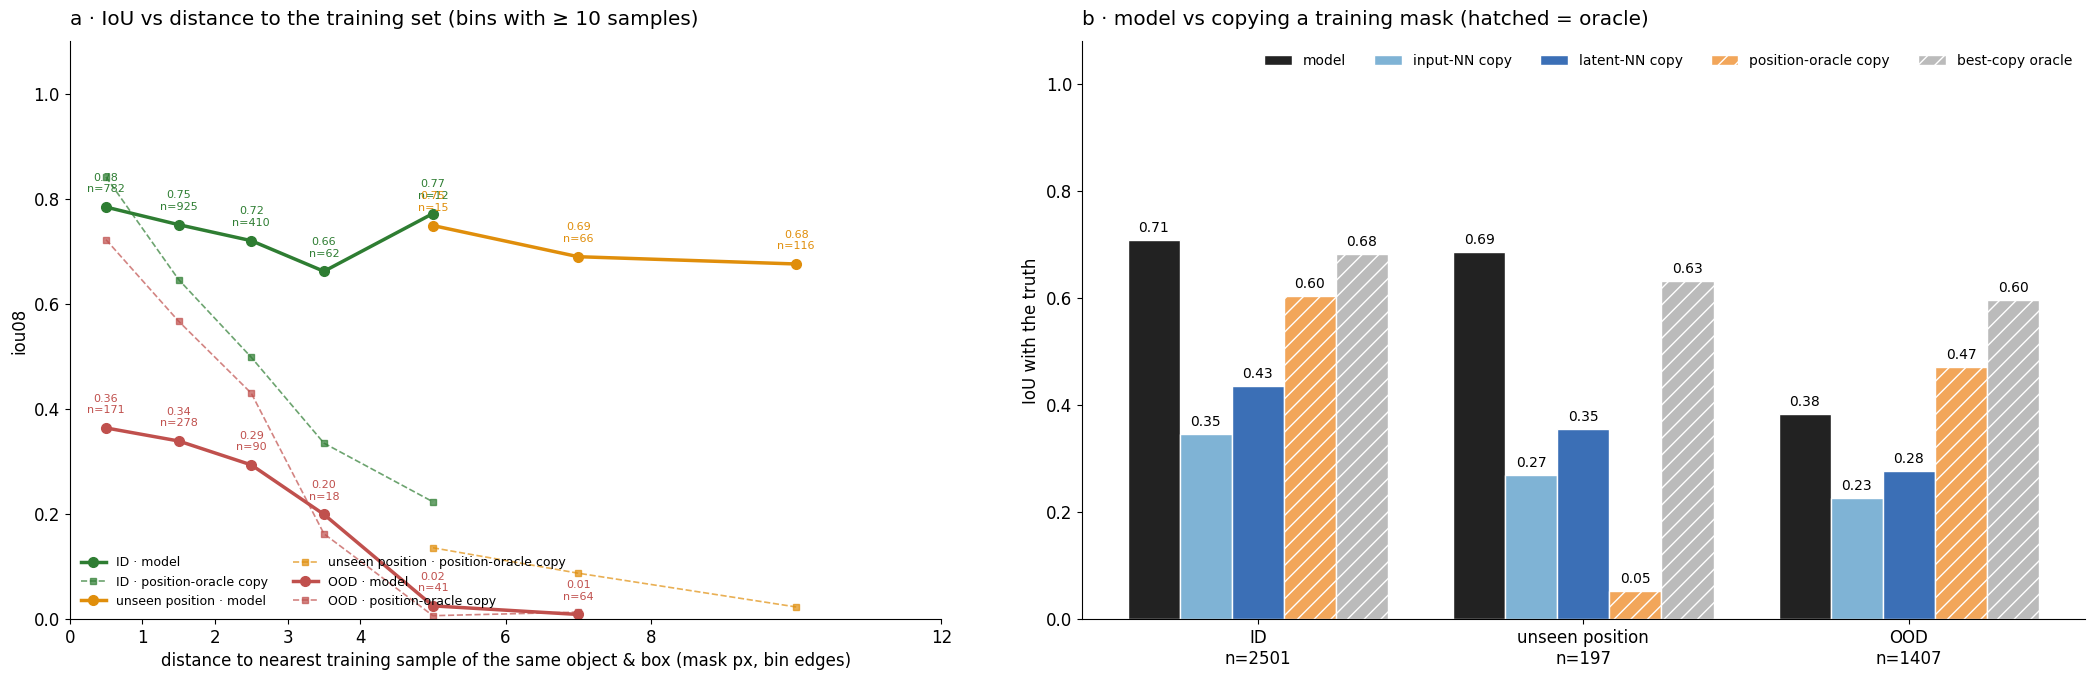

ID
         model  oracle    n
bin                        
[0, 1)   0.784   0.842  782
[1, 2)   0.751   0.646  925
[2, 3)   0.720   0.498  410
[3, 4)   0.662   0.334   62
[4, 6)   0.772   0.223   12
[6, 8)     NaN     NaN    0
[8, 12)    NaN     NaN    0
unseen position
         model  oracle    n
bin                        
[0, 1)     NaN     NaN    0
[1, 2)     NaN     NaN    0
[2, 3)     NaN     NaN    0
[3, 4)     NaN     NaN    0
[4, 6)   0.749   0.135   15
[6, 8)   0.690   0.087   66
[8, 12)  0.676   0.022  116
OOD
         model  oracle    n
bin                        
[0, 1)   0.363   0.722  171
[1, 2)   0.339   0.567  278
[2, 3)   0.293   0.430   90
[3, 4)   0.199   0.162   18
[4, 6)   0.024   0.006   41
[6, 8)   0.008   0.013   64
[8, 12)  0.138   0.000    8
                   iou  input_nn  latent_nn  position_oracle  best_copy
group                                                                  
ID               0.708     0.346      0.435            0.604      0.682
unsee

In [12]:
GROUP_COLOURS = {"ID": "#2E7D32", "unseen position": "#E08E0B", "OOD": "#C0504D"}
EDGES = [0, 1, 2, 3, 4, 6, 8, 12]
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(26, 7.5), gridspec_kw=dict(width_ratios=[1, 1.15], wspace=0.15))
single = copies[(copies.n_obj == 1) & copies.distance.notna()].copy()
single["bin"] = pd.cut(single.distance, EDGES, right=False)
centres = [(a + b) / 2 for a, b in zip(EDGES[:-1], EDGES[1:])]
distance_table = {}
for group, colour in GROUP_COLOURS.items():
    g = single[single.group == group].groupby("bin", observed=False).agg(model=("iou", "mean"), oracle=("position_oracle", "mean"), n=("iou", "size"))
    keep = (g.n >= 10).to_numpy()
    xs = np.array(centres)[keep]
    ax_a.plot(xs, g.model[keep], "o-", color=colour, lw=2.5, ms=7, label=f"{group} · model")
    ax_a.plot(xs, g.oracle[keep], "s--", color=colour, lw=1.2, ms=4, alpha=0.7, label=f"{group} · position-oracle copy")
    for xv, yv, nv in zip(xs, g.model[keep], g.n[keep]):
        ax_a.text(xv, yv + 0.025, f"{yv:.2f}\nn={nv}", ha="center", va="bottom", fontsize=8, color=colour)
    distance_table[group] = g
ax_a.set_xticks(EDGES, [str(e) for e in EDGES])
ax_a.set_xlim(0, 12)
ax_a.set_xlabel("distance to nearest training sample of the same object & box (mask px, bin edges)")
ax_a.set_ylabel("iou08")
ax_a.set_ylim(0, 1.1)
ax_a.legend(frameon=False, fontsize=9, ncol=2, loc="lower left")
ax_a.set_title("a · IoU vs distance to the training set (bins with ≥ 10 samples)", loc="left", pad=12)

methods = [("iou", "model", "#222222"), ("input_nn", "input-NN copy", "#7FB3D5"), ("latent_nn", "latent-NN copy", "#3B6FB6"),
           ("position_oracle", "position-oracle copy", "#F2A65A"), ("best_copy", "best-copy oracle", "#BBBBBB")]
groups = list(GROUP_COLOURS)
copy_table = copies[copies.group != "other"].groupby("group")[[m for m, _, _ in methods]].mean().reindex(groups)
w = 0.16
for i, (column, label, colour) in enumerate(methods):
    bars = ax_b.bar(np.arange(len(groups)) + (i - 2) * w, copy_table[column], w, color=colour, label=label, hatch="//" if "oracle" in label else None, edgecolor="white")
    bar_labels(ax_b, bars, fontsize=10)
ax_b.set_xticks(np.arange(len(groups)), [f"{g}\nn={(copies.group == g).sum()}" for g in groups])
ax_b.set_ylabel("IoU with the truth")
ax_b.set_ylim(0, 1)
ax_b.legend(frameon=False, ncol=5, loc="upper right", fontsize=10)
ax_b.set_ylim(0, 1.08)
ax_b.set_title("b · model vs copying a training mask (hatched = oracle)", loc="left", pad=12)
fig.savefig(OUT / "interpolation.svg", bbox_inches="tight")
plt.show()
for group, g in distance_table.items():
    print(group)
    print(g.round(3).to_string())
print(copy_table.round(3).to_string())
print(copies[copies.group != "other"].groupby(["group", "box"])[["iou", "input_nn", "latent_nn", "position_oracle", "best_copy"]].mean().round(3).to_string())
print("input NN picks the same object:", copies[copies.group != "other"].groupby("group").input_nn_same_object.mean().round(3).to_dict())
print("model beats the position oracle on:", copies[copies.group != "other"].assign(win=lambda d: d.iou > d.position_oracle).groupby("group").win.mean().round(3).to_dict())

**Claims (Figure 4)**
- **The model is not a lookup table of inputs.**
  - Copying the mask of the nearest training input (cosine, same box) gives .35 ID / .27 unseen-position / .23 OOD, against the model's .71 / .69 / .38.
  - Even the nearest neighbour in the model's own latent space only reaches .43 / .35 / .28.
  - The nearest input has the right object only 86% of the time on ID.
- **In-distribution, the model beats every copy baseline, including the oracles.**
  - ID .708 vs .604 for the position oracle (the same object's nearest training position, using the true answer) and .682 for the best possible copied training mask.
  - The model beats the position oracle on 69% of ID samples.
  - It produces masks that do not exist in the training set.
- **It interpolates smoothly between training positions.** The position-oracle copy degrades fast with distance to the nearest same-object training sample (ID .84 at < 1 px → .33 at 3–4 px). The model stays flat (.78 → .66).
- **It extrapolates to unseen positions.** On the held-out vase region (4–12 px from any training vase) the position oracle drops to .05, but the model keeps .69 (.75 at 4–6 px, .68 at 8–12 px). It beats the oracle on 100% of those samples, and also beats the best copy of any training mask (.632).
- **OOD is where the model falls below the oracles.**
  - OOD model .38 vs position oracle .47 and best copy .60. The model wins on only 38% of OOD samples.
  - At 4–8 px from the nearest same-object training sample, OOD IoU is .01–.02. These are almost all cardboard cylinders of 4–21 px.
  - The gap is about reading the unseen condition (speaker, lasers, lid, new object), not about not knowing where things can be.